# JavaScript Arrays and Objects

A comprehensive guide to JavaScript objects, prototypes, arrays, and iteration. This course covers how objects and arrays work under the hood — from prototype chains and property descriptors to deep copying, array manipulation, and functional iteration patterns.


## Table of Contents

1. [Module 01: Course Overview](#module-01-course-overview)
2. [Module 02: Prototypes and Properties](#module-02-prototypes-and-properties)
3. [Module 03: Object References and Scope](#module-03-object-references-and-scope)
4. [Module 04: Arrays](#module-04-arrays)
5. [Module 05: Array Iteration Deep Dive](#module-05-array-iteration-deep-dive)


In [1]:
from pathlib import Path
from IPython.display import HTML, display
import base64

def render_diagram(image_path, width=900):
    data = base64.b64encode(Path(image_path).read_bytes()).decode()
    display(HTML(f'<div style="text-align:center"><img src="data:image/png;base64,{data}" width="{width}"/></div>'))


## Module 01: Course Overview

_Introduction to common points of confusion with JavaScript objects and arrays, and a high-level map of the topics covered._

### Common Points of Confusion

JavaScript developers frequently struggle with three core concepts:

- **What's the difference between a prototype and a class?** — JavaScript is a *prototype-based* language; classes are syntactic sugar over the prototype system.
- **What does it mean that objects are reference types?** — Variables holding objects store a memory address, not the object itself; this affects assignment, comparison, and passing to functions.
- **All the array functions out there** — `forEach`, `map`, `filter`, `reduce`, `find`, `some`, `every`, and more — each with different return values and use cases.

> Arrays are objects — they are a specialised form of object with numeric keys and an `Array.prototype` chain.

### Course Scope

This course focuses on how objects and arrays *work* in JavaScript, not on object-oriented design principles or class hierarchies. Topics covered:

**Objects**
- What is an Object? · Defining Prototypes with `Object.create` · Creating, Accessing, Deleting, Protecting, and Enumerating Properties · Objects as Reference Types · Comparing and Cloning Objects · Functions as Properties · Scope in Objects · Object Wrappers of Primitives

**Arrays**
- Creating, Identifying, and Accessing Array Elements · Slicing and Splicing · Concatenating and Cloning Arrays · Sorting · Sparse Arrays · Maps, Sets, and Typed Arrays

**Iteration**
- Introduction to Array Iteration · Basic For Loops · `forEach` · Summarising Arrays (`reduce`, `join`, `some`, `every`) · Searching (`find`, `filter`, `includes`) · `map` and Functional JavaScript


## Module 02: Prototypes and Properties

_Covers what JavaScript objects are, how the prototype chain works, creating objects three ways, and every CRUD operation on properties._

### What is an Object?

An object is a container for other datatypes. A `User` might hold `id` (number), `username` (string), `timezone` (string), and so on. Each named slot is called a **property**.

Three fundamental facts about JavaScript objects:

1. **Containers for other datatypes** — properties can hold any value, including other objects and functions.
2. **Passed via reference** — a variable doesn't hold the object itself; it holds a pointer to the object in memory (heap).
3. **Link to a prototype** — every object has a hidden `[[Prototype]]` link that defines inherited behaviour.



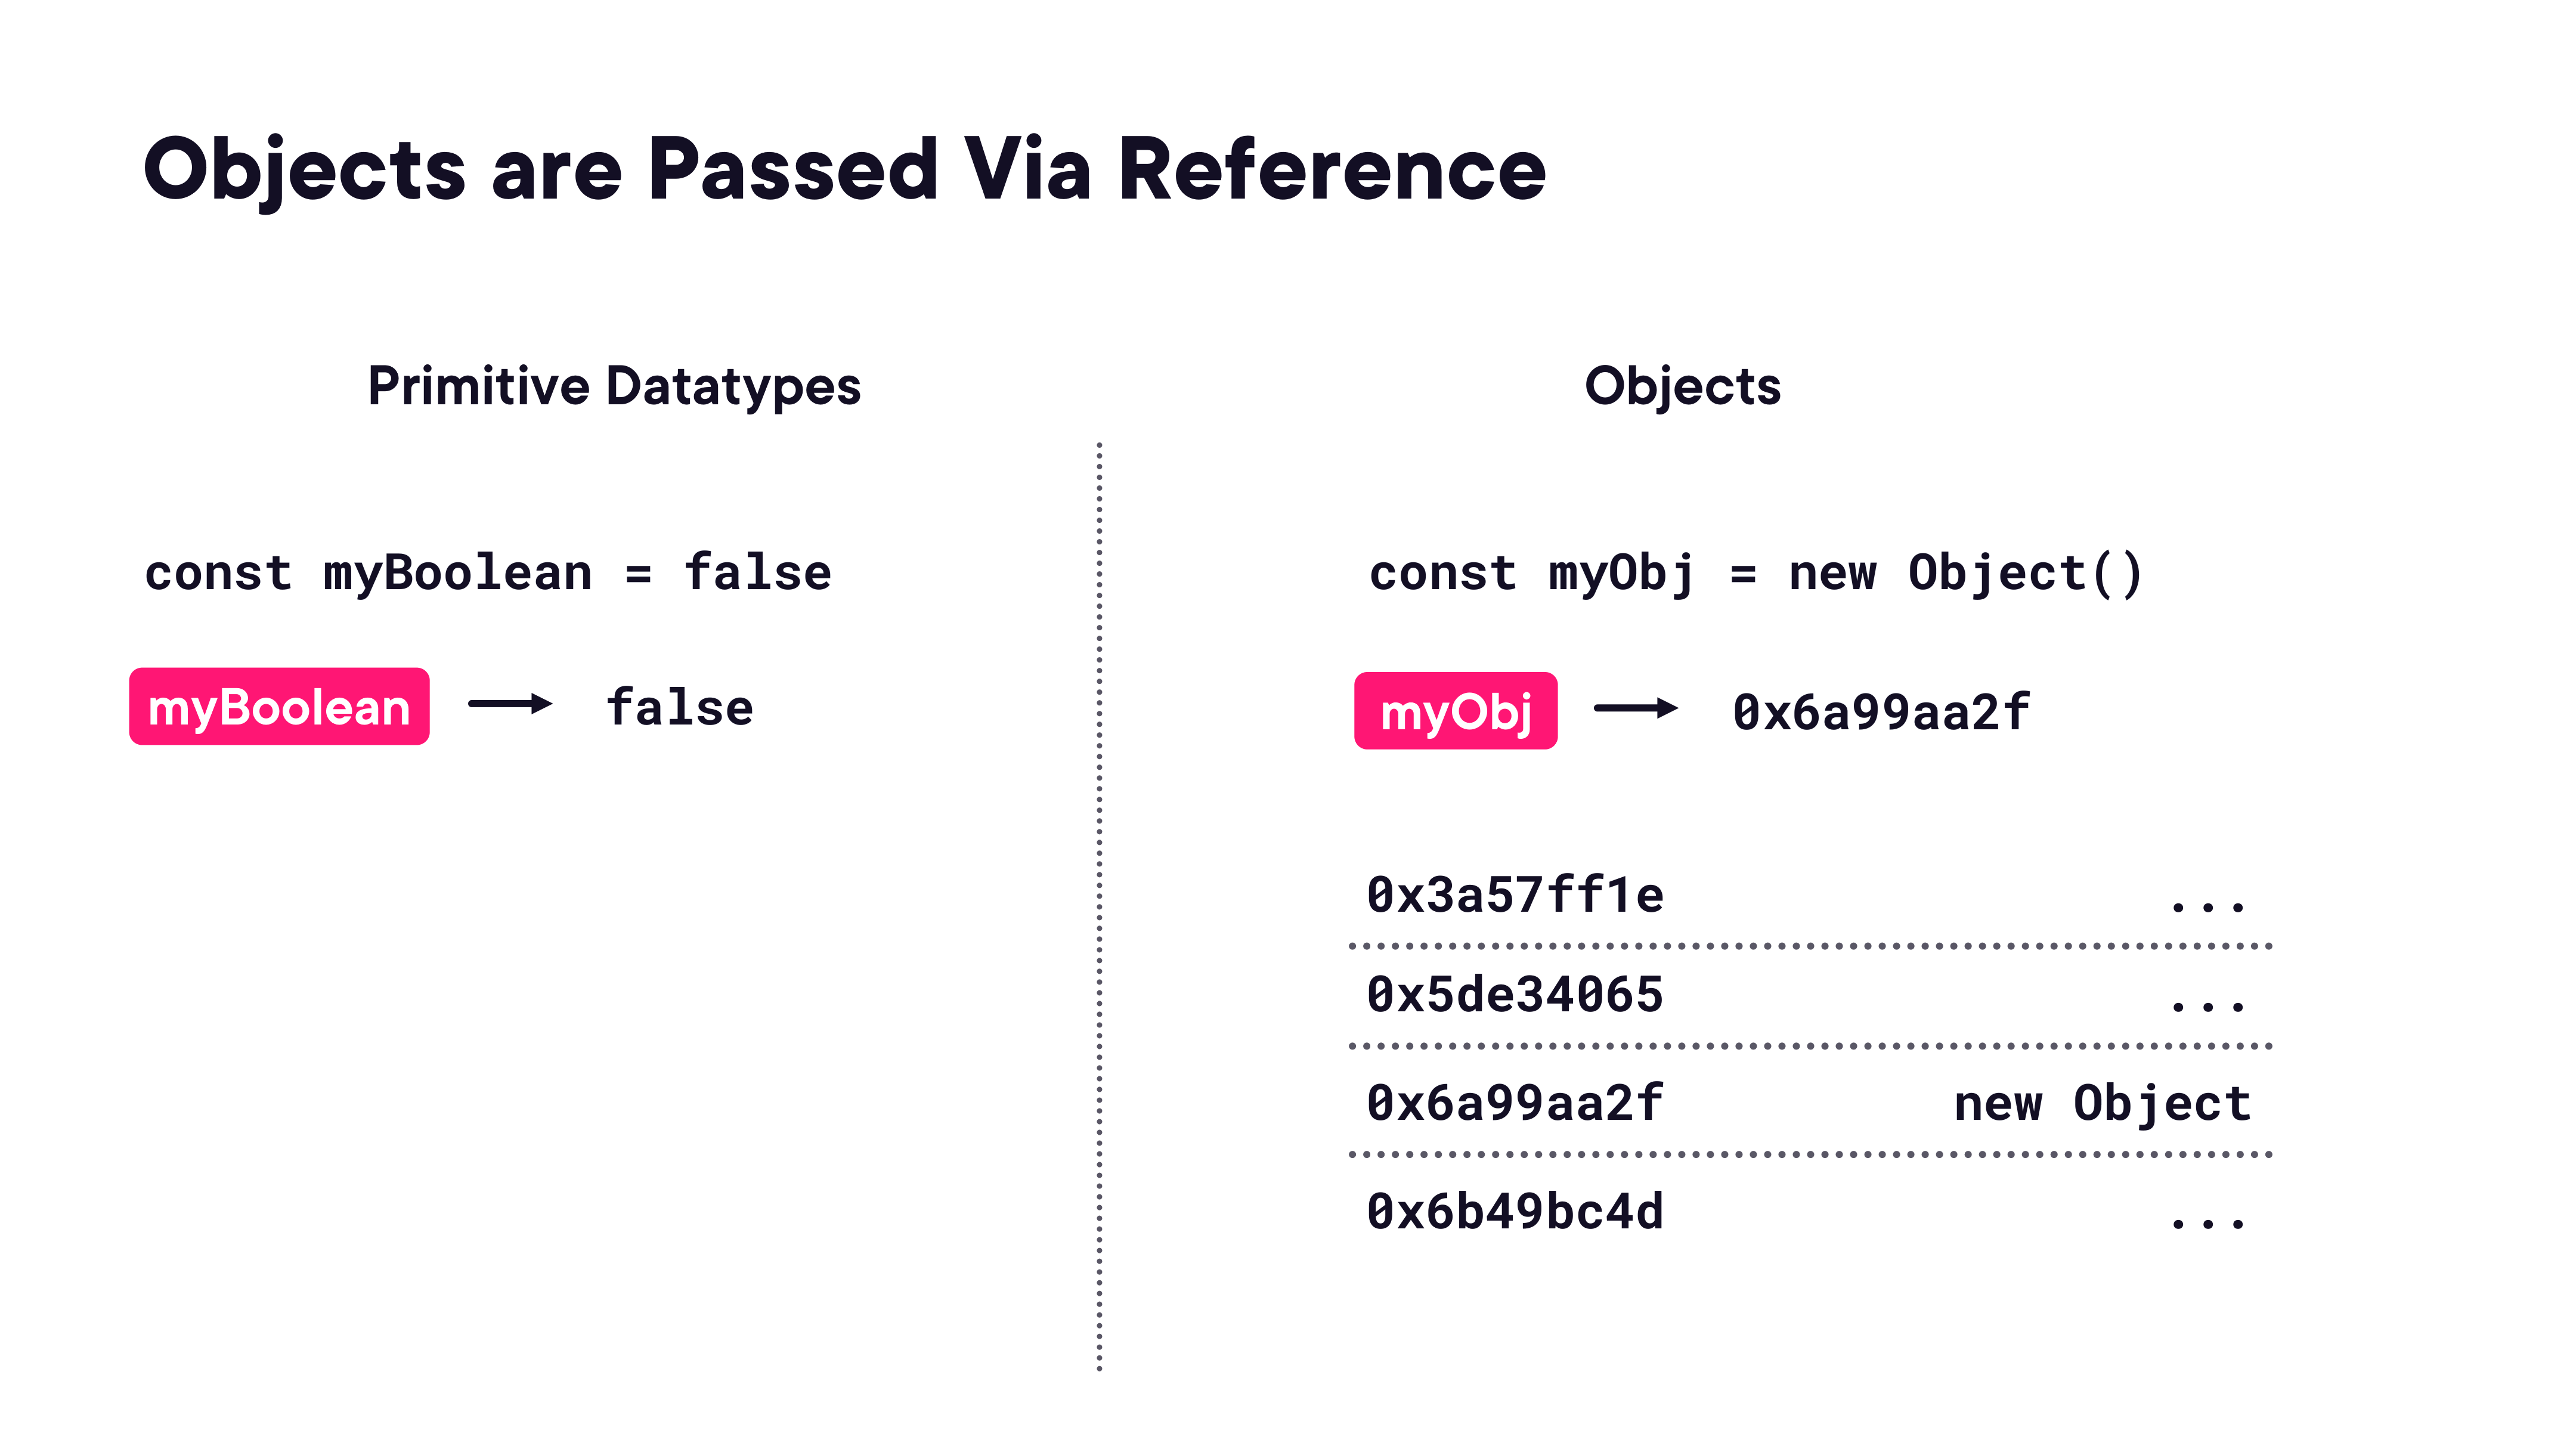

In [2]:
render_diagram(Path("assets/01-objects-reference-types.png"))

### Creating Objects

Three ways to create objects:

**1. Object literal** — most common:
```javascript
const myCourse = {
  title: "Arrays and Objects in JavaScript",
  id: "ps_js-arrobj"
};
```

**2. `new` syntax** — used for built-in types and constructors:
```javascript
const myDate = new Date();
myDate.getDate(); // e.g. 24
```

**3. `Object.create(prototype)`** — explicitly sets the prototype:
```javascript
const myObj = Object.create(Object.prototype); // same as {}
const myNullObj = Object.create(null);         // no prototype at all
```

#### Object Literals and JSON

Object literals and JSON look similar but are distinct:

```javascript
// Object literal — keys don't need quotes
const myCourse = {
  title: "Arrays and Objects",
  id: "ps_js-arrobj",
};

// JSON — all keys must be double-quoted strings, no trailing comma
{
  "title": "Arrays and Objects",
  "id": "ps_js-arrobj"
}
```

JSON is a data transport format; an object literal is a JavaScript expression.

#### `object` vs `Object`

| Term | Meaning |
|---|---|
| `object` (lowercase) | The general datatype — any non-primitive value |
| `Object` (uppercase) | A specific built-in — `Object.prototype`, `Object.create`, etc. |

All objects ultimately link to `Object.prototype`.

### What is a Prototype?

JavaScript has ~20 **Standard Built-in Objects**: `Date`, `Array`, `String`, `Map`, `Set`, `RegExp`, `Promise`, `Error`, `Math`, `JSON`, and more. Each provides a `.prototype` object containing shared methods.

**Key takeaways:**
- Many objects are predefined in the runtime — you don't have to create them.
- Objects link to prototypes which define their behaviour (methods).
- When you access a property, JavaScript walks the **prototype chain** until it finds it (or reaches `null`).

### Traversing the Prototype Chain



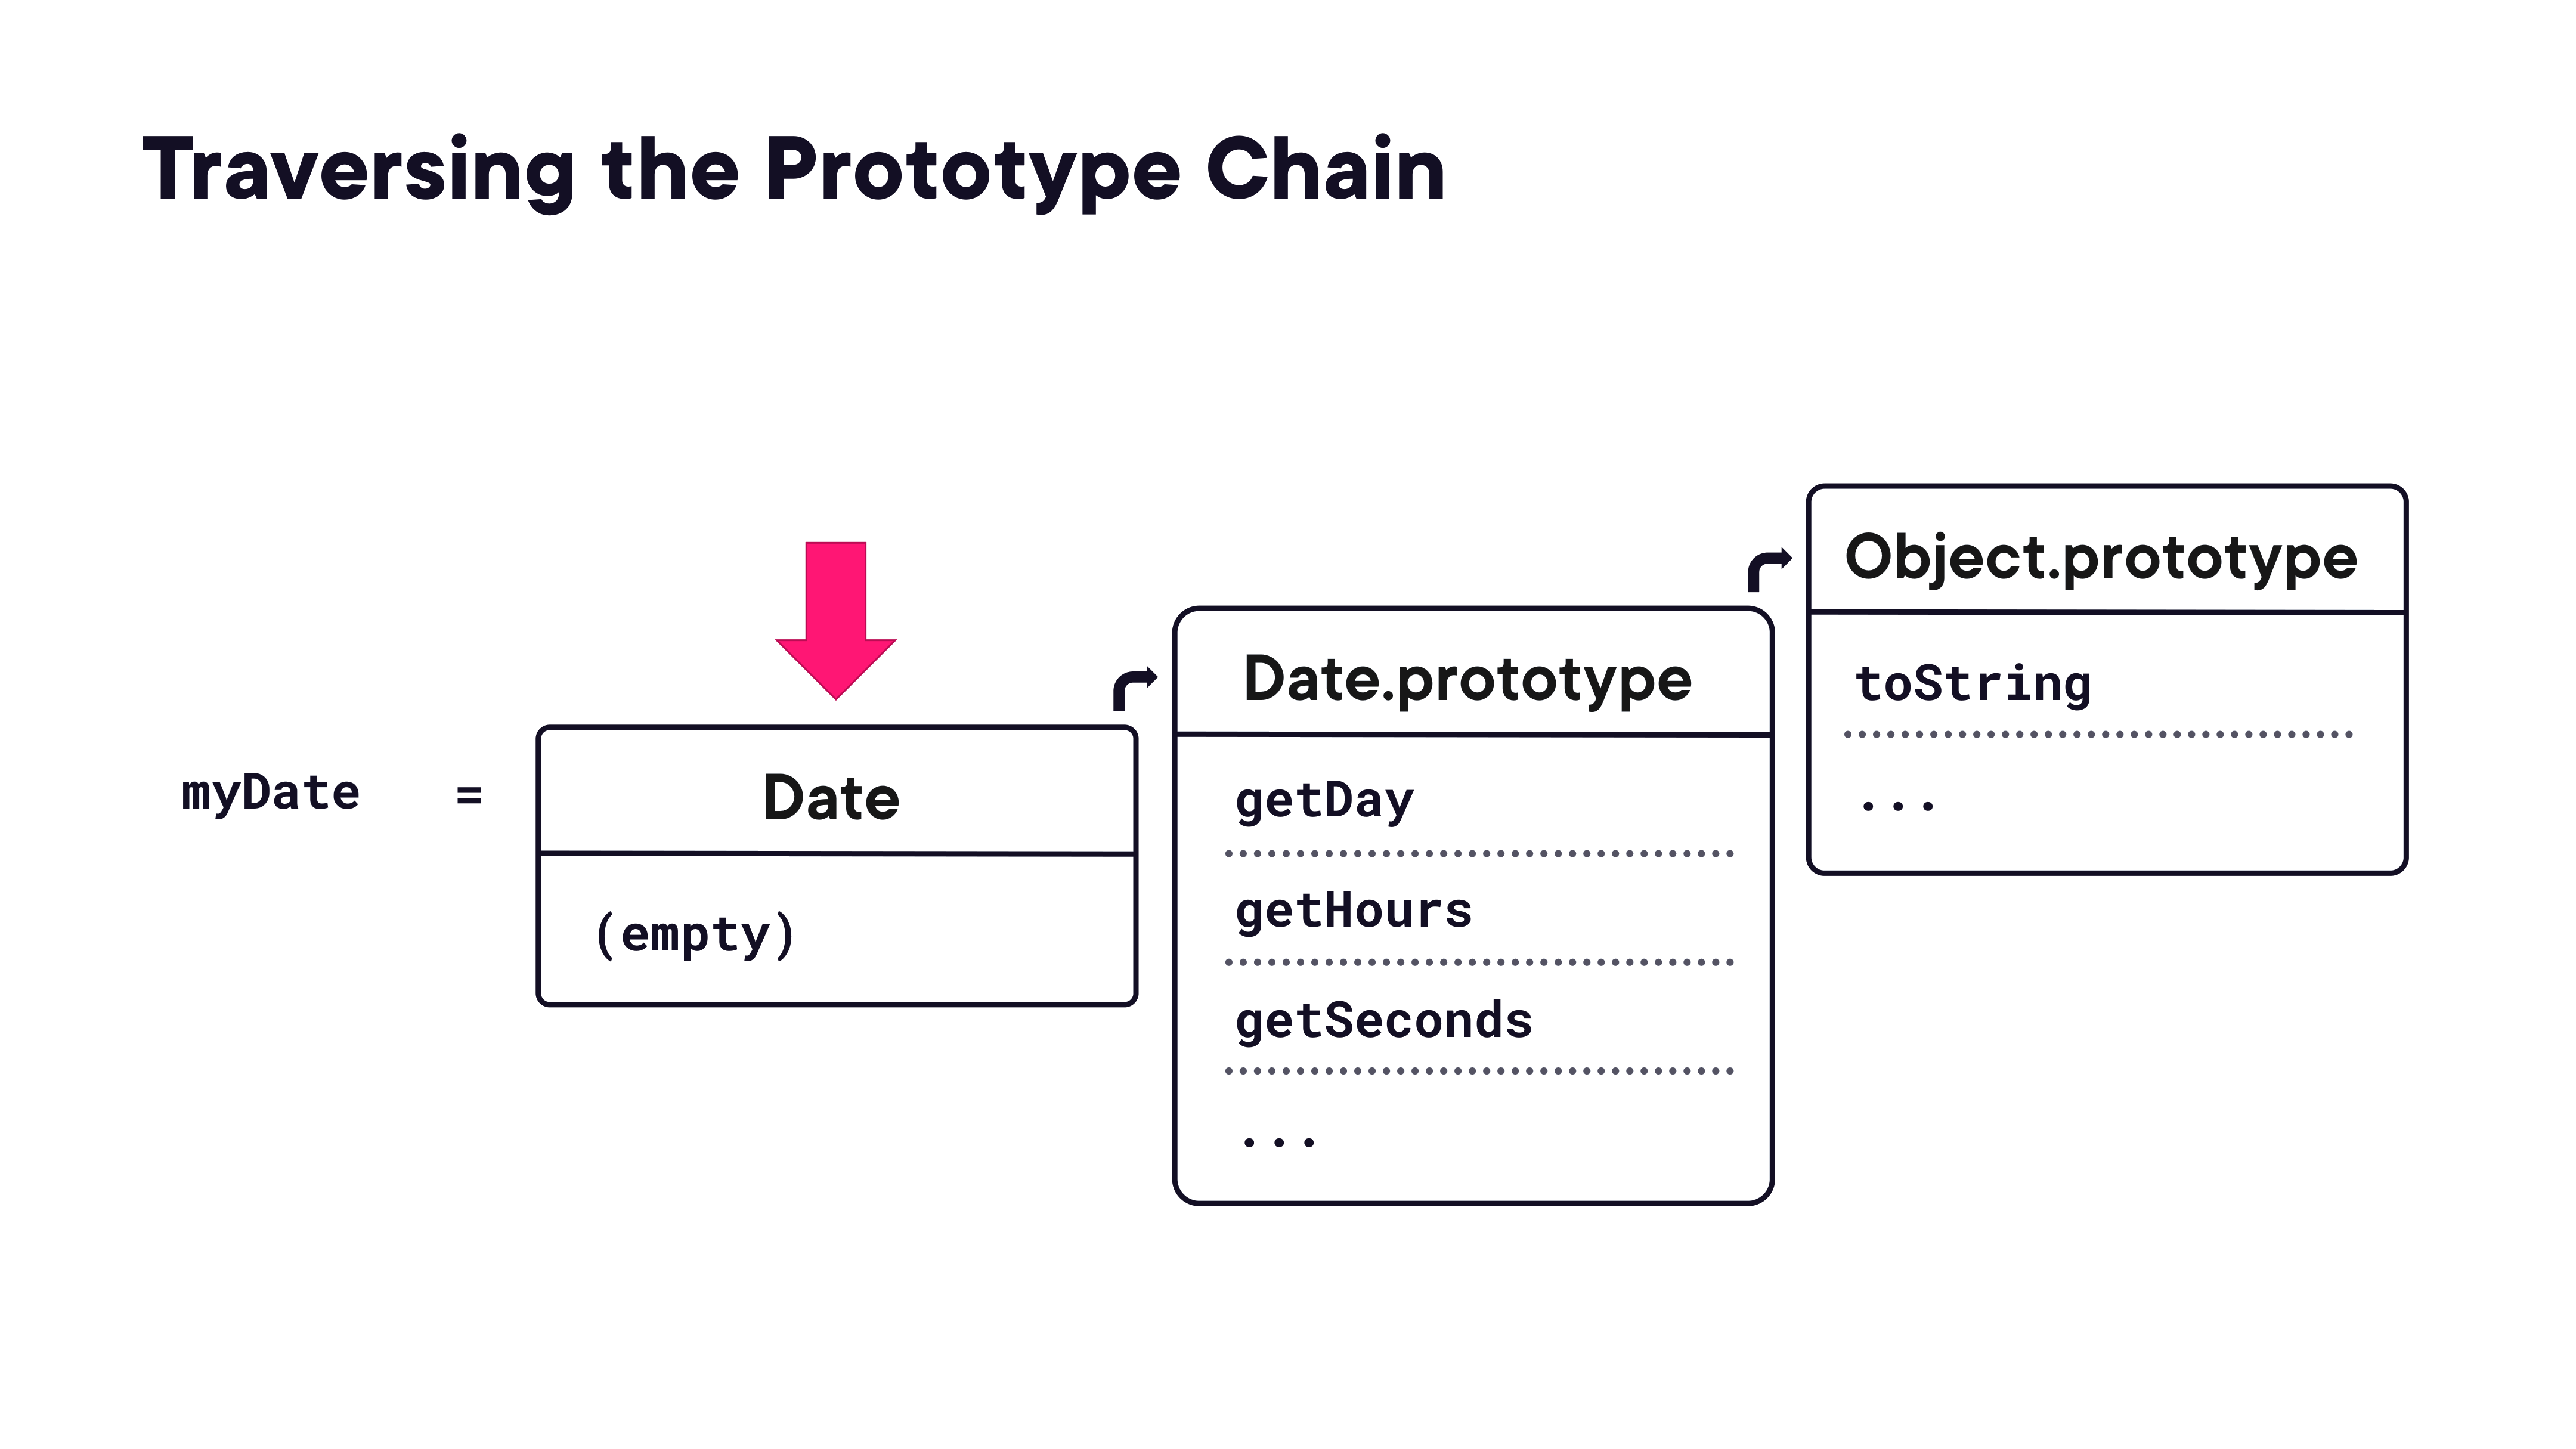

In [3]:
render_diagram(Path("assets/02-prototype-chain-traversal.png"))

When you call `myDate.toString()`:
1. JavaScript looks on `myDate` itself — not found.
2. Looks on `Date.prototype` (`getDay`, `getHours`, `getSeconds`, …) — not found.
3. Looks on `Object.prototype` (`toString`, …) — **found**.

The chain always terminates at `Object.prototype`, whose own `[[Prototype]]` is `null`.

### Defining Prototypes with `Object.create`

```javascript
const courseProto = {
  title: "No title",
  id: "No id",
  author: "No author"
};

const newCourse = Object.create(courseProto);
// newCourse is empty; newCourse.title resolves via the chain → "No title"

newCourse.title = "My Course";
// now newCourse owns title → "My Course"
// courseProto.title is unchanged
```

The three creation methods compared:

| Syntax | Object | Date |
|---|---|---|
| Object literal | `const o = { ... }` | — |
| `new` | `const o = new Object()` | `const d = new Date()` |
| `Object.create` | `Object.create(Object.prototype)` | `Object.create(Date.prototype)` |

### Creating Properties

Properties can be created by assignment at any time:

```javascript
// Dot notation — shorthand, preferred
contentBlock1.color = "#00aced";

// Bracket notation — required for computed or illegal identifier names
contentBlock["info" + i] = "info";
for (let i = 0; i < 5; i++) {
  contentBlock["info" + i] = "info";
}
```

#### Dot Notation vs. Bracket Notation

| | Dot Notation | Bracket Notation |
|---|---|---|
| Syntax | `obj.prop` | `obj["prop"]` |
| Illegal identifiers | ✗ | ✓ |
| Computed at runtime | ✗ | ✓ |

### Accessing Properties

Property lookup walks the prototype chain from the object outward. When a property is set directly on the object it **shadows** the prototype's version.

Checking for property existence:

```javascript
// Check own + inherited (any value including undefined)
if ("property" in object) { ... }

// Check own properties only (modern)
if (Object.hasOwn(object, "property")) { ... }

// Avoid — fragile if the property is intentionally set to undefined
if (object.property !== undefined) { ... }
```

### Deleting Properties

```javascript
delete contentBlock1.color;
// contentBlock1.color now resolves via the prototype chain again
```

`delete` only removes the **own** property; it never affects the prototype.

### Protecting Properties

#### Property Attributes (Descriptors)

Every property carries three boolean attributes alongside its value:

| Attribute | Question it answers | Default (assignment) |
|---|---|---|
| `writable` | Can the value be changed? | `true` |
| `enumerable` | Does it appear in `Object.keys()` / `for...in`? | `true` |
| `configurable` | Can it be deleted, or can its attributes be changed? | `true` |

Read a property's descriptor with `Object.getOwnPropertyDescriptor`:

```javascript
const obj = { title: "Cybersecurity" };
Object.getOwnPropertyDescriptor(obj, "title");
// { value: "Cybersecurity", writable: true, enumerable: true, configurable: true }
```

Set attributes explicitly with `Object.defineProperty`:

```javascript
Object.defineProperty(obj, "title", {
  value: "Cybersecurity",
  writable: false,      // value cannot be changed
  configurable: false,  // descriptor cannot be changed; property cannot be deleted
  enumerable: true      // still shows up in Object.keys()
});

obj.title = "Other"; // silently fails (throws in strict mode)
delete obj.title;    // silently fails (throws in strict mode)
```

Define multiple properties at once with `Object.defineProperties`:

```javascript
Object.defineProperties(obj, {
  id:    { value: "42",  writable: false, enumerable: true, configurable: false },
  title: { value: "JS",  writable: true,  enumerable: true, configurable: true  },
});
```

#### Locking Down Entire Objects

JavaScript provides three methods that apply attribute restrictions across an **entire object** at once, each progressively stricter:

| Feature | `preventExtensions()` | `seal()` | `freeze()` |
|---|:---:|:---:|:---:|
| Add new properties | ❌ | ❌ | ❌ |
| Delete existing properties | ✅ | ❌ | ❌ |
| Change existing property values | ✅ | ✅ | ❌ |
| Reconfigure property descriptors | Some restrictions | ❌ | ❌ |
| `Object.isExtensible()` | `false` | `false` | `false` |
| `Object.isSealed()` | not necessarily | `true` | `true` |
| `Object.isFrozen()` | not necessarily | not necessarily | `true` |

```javascript
// preventExtensions — no new properties can be added; existing ones are untouched
const obj1 = { id: 1, title: "JS" };
Object.preventExtensions(obj1);
obj1.newProp = "x";  // silently ignored (throws in strict mode)
obj1.title = "TS";   // ✅ still works
delete obj1.id;      // ✅ still works
Object.isExtensible(obj1); // false

// seal — no add, no delete, no reconfigure; values can still change
const obj2 = { id: 1, title: "JS" };
Object.seal(obj2);
obj2.newProp = "x";  // ❌ ignored
delete obj2.id;      // ❌ ignored
obj2.title = "TS";   // ✅ value change is allowed
Object.isSealed(obj2); // true

// freeze — completely immutable: no add, no delete, no value change
const obj3 = { id: 1, title: "JS" };
Object.freeze(obj3);
obj3.title = "TS";   // ❌ ignored (throws in strict mode)
obj3.newProp = "x";  // ❌ ignored
delete obj3.id;      // ❌ ignored
Object.isFrozen(obj3); // true
```

> `freeze` is a **shallow** operation — nested objects are not frozen automatically. To deeply freeze an object tree you must recurse and freeze each nested object yourself.

#### Checking the State of an Object

```javascript
Object.isExtensible(obj); // false after preventExtensions, seal, or freeze
Object.isSealed(obj);     // true after seal or freeze
Object.isFrozen(obj);     // true only after freeze
```

### Enumerating Properties

**Enumerable** means "able to be counted or named, one by one."



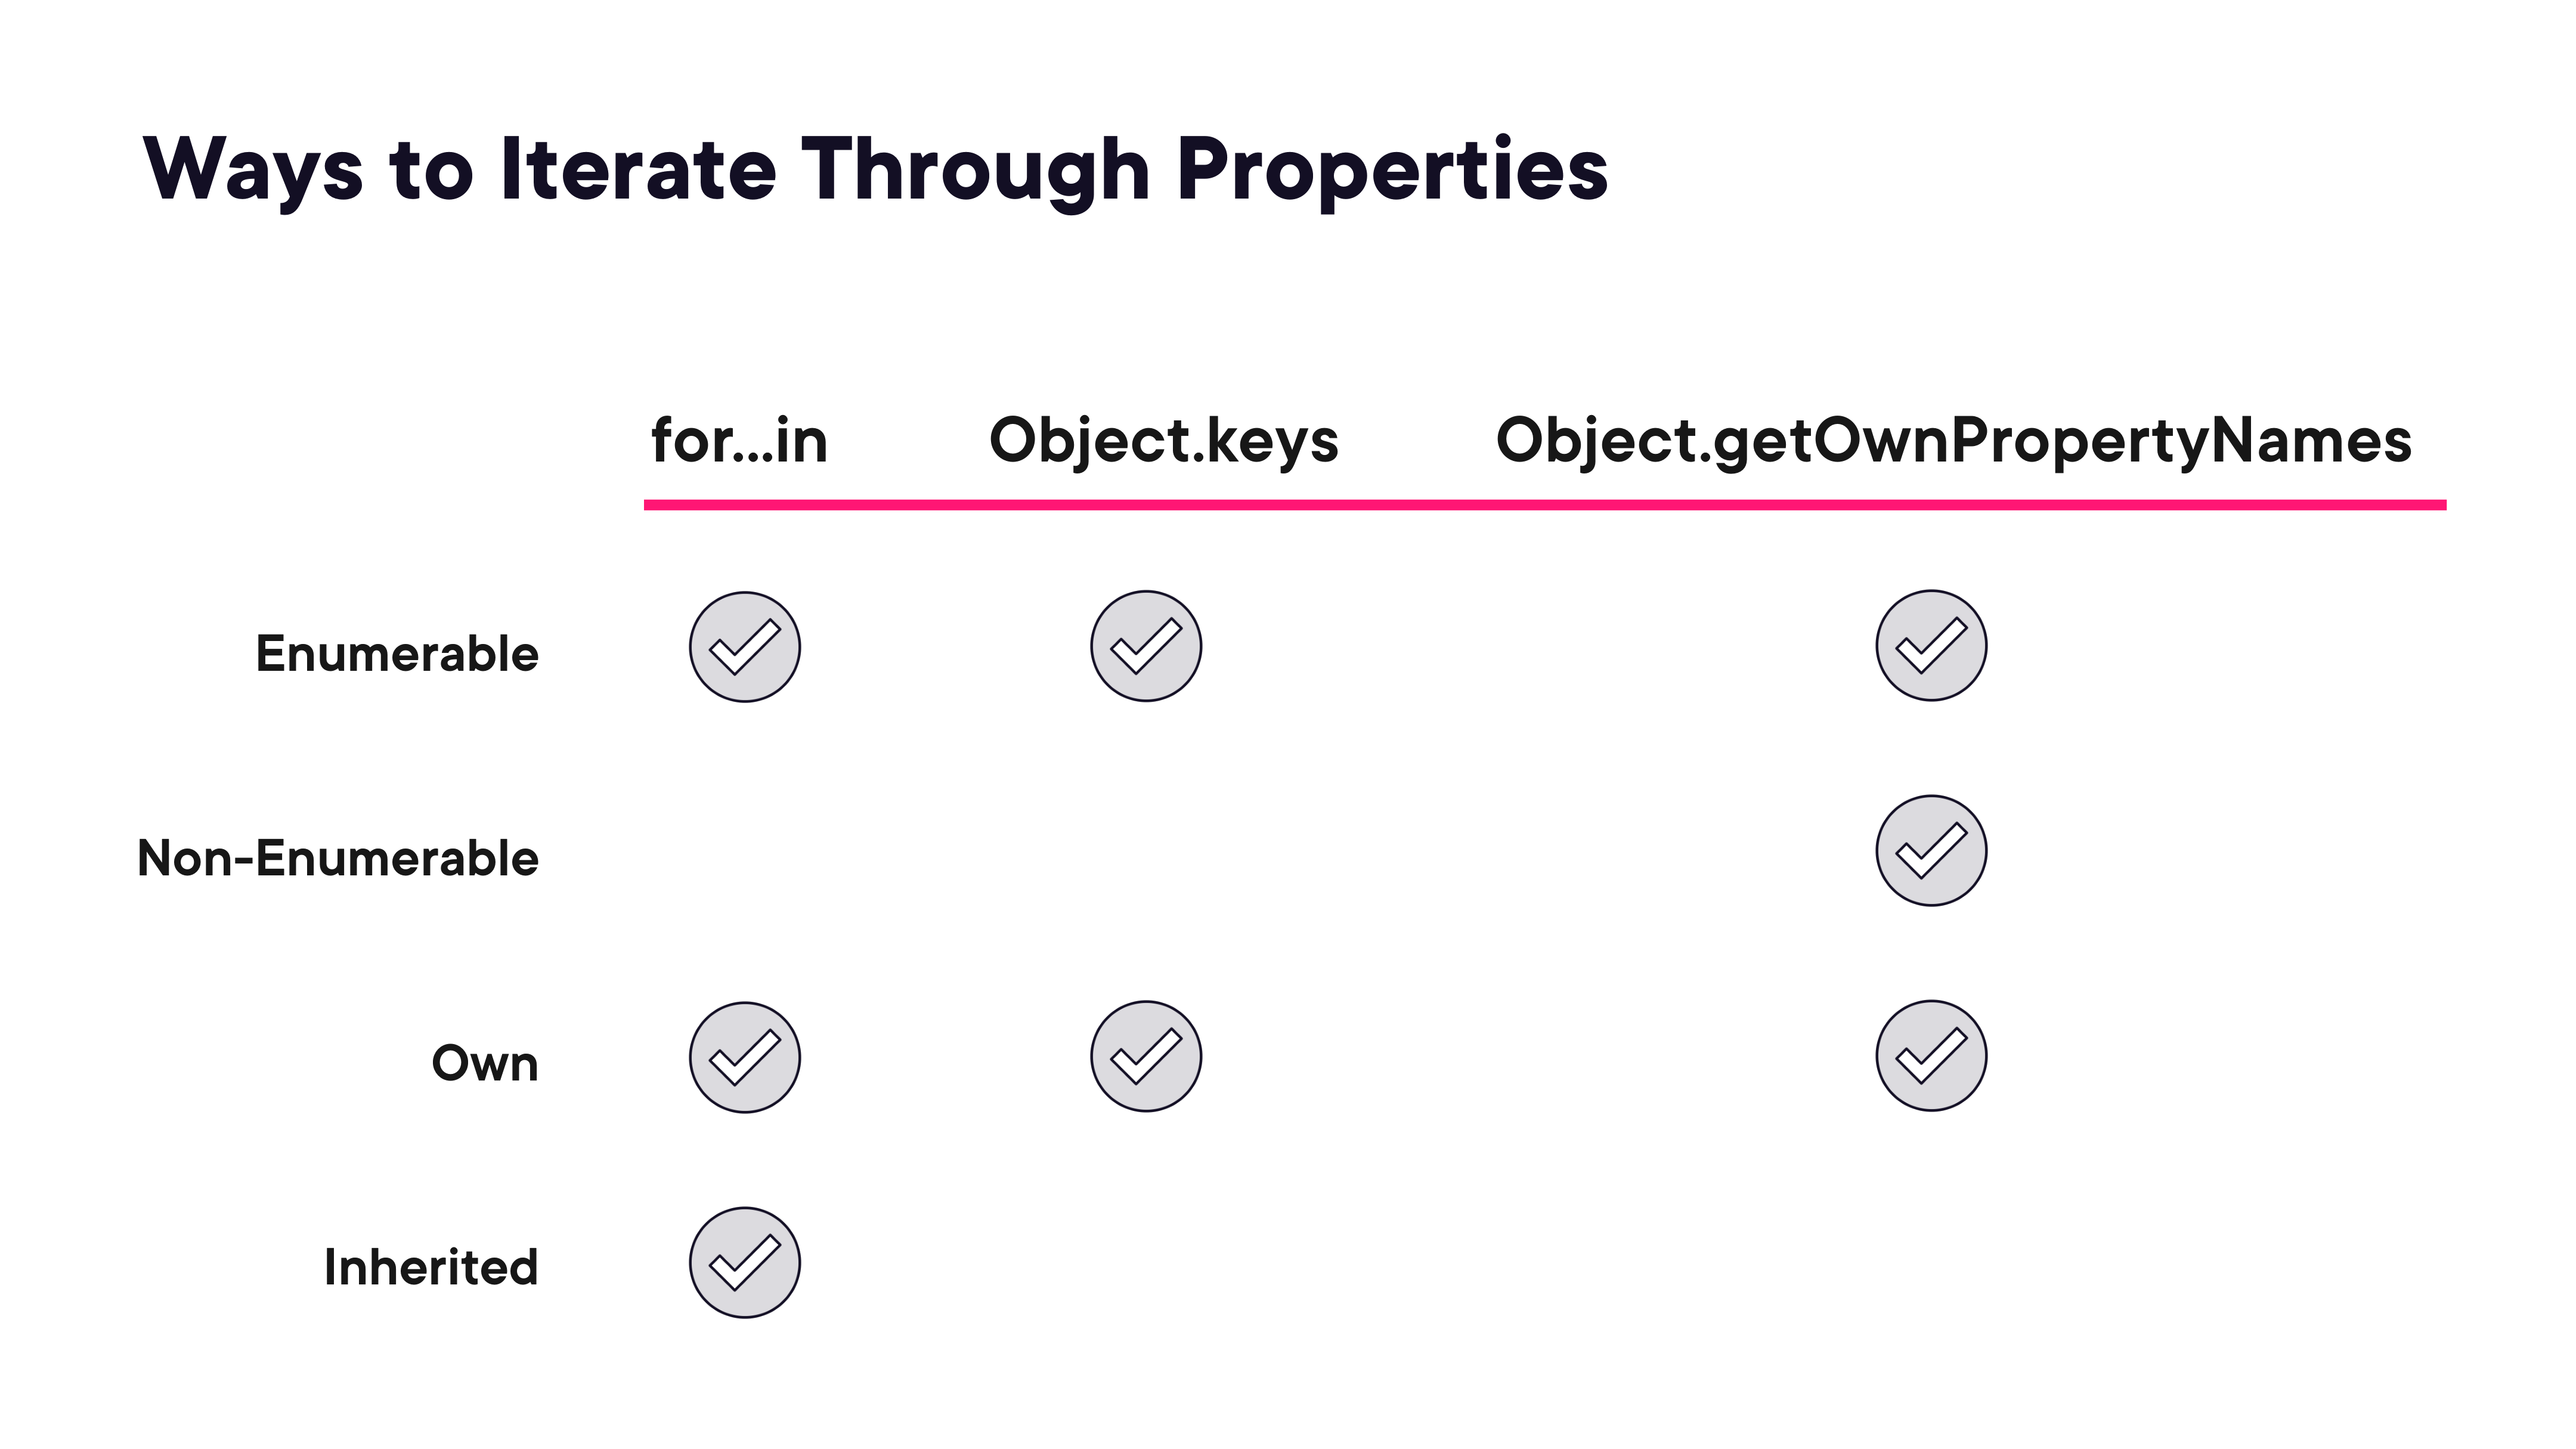

In [4]:
render_diagram(Path("assets/03-property-iteration-matrix.png"))

Three methods for iterating properties, each with different scope:

| Method | Enumerable | Non-Enumerable | Own | Inherited |
|---|:---:|:---:|:---:|:---:|
| `for...in` | ✓ | | ✓ | ✓ |
| `Object.keys` | ✓ | | ✓ | |
| `Object.getOwnPropertyNames` | ✓ | ✓ | ✓ | |

```javascript
// for...in — all enumerable properties, own AND inherited
for (let key in obj) { console.log(key); }

// Object.keys — only enumerable own properties
Object.keys(obj).forEach(key => console.log(key));

// Object.getOwnPropertyNames — all own properties including non-enumerable
Object.getOwnPropertyNames(obj).forEach(key => console.log(key));
```

**Summary — JavaScript Object Prototypes**
- Many objects are predefined for you in the runtime.
- Objects link to prototypes which define their behaviour.
- Property access walks the prototype chain.
- Object literals link to `Object.prototype`.
- `Object.prototype` sits at the end of all prototype chains.
- An object's prototype is set via `new` syntax or `Object.create()`.


## Module 03: Object References and Scope

_Deep dive into how objects live in memory, why reference semantics matter, how to compare and clone objects, functions as properties, `this`, and primitive wrappers._

### Objects are Reference Types

**`const` vs `let`**

| | `const` | `let` |
|---|---|---|
| Can be redefined | ✗ | ✓ |
| Example | `const myNum = 1.138;` | `let myNum = 1.138;` |

`const` prevents *reassignment* of the variable binding. It does **not** prevent mutation of the object the variable points to.

### Stack vs. Heap



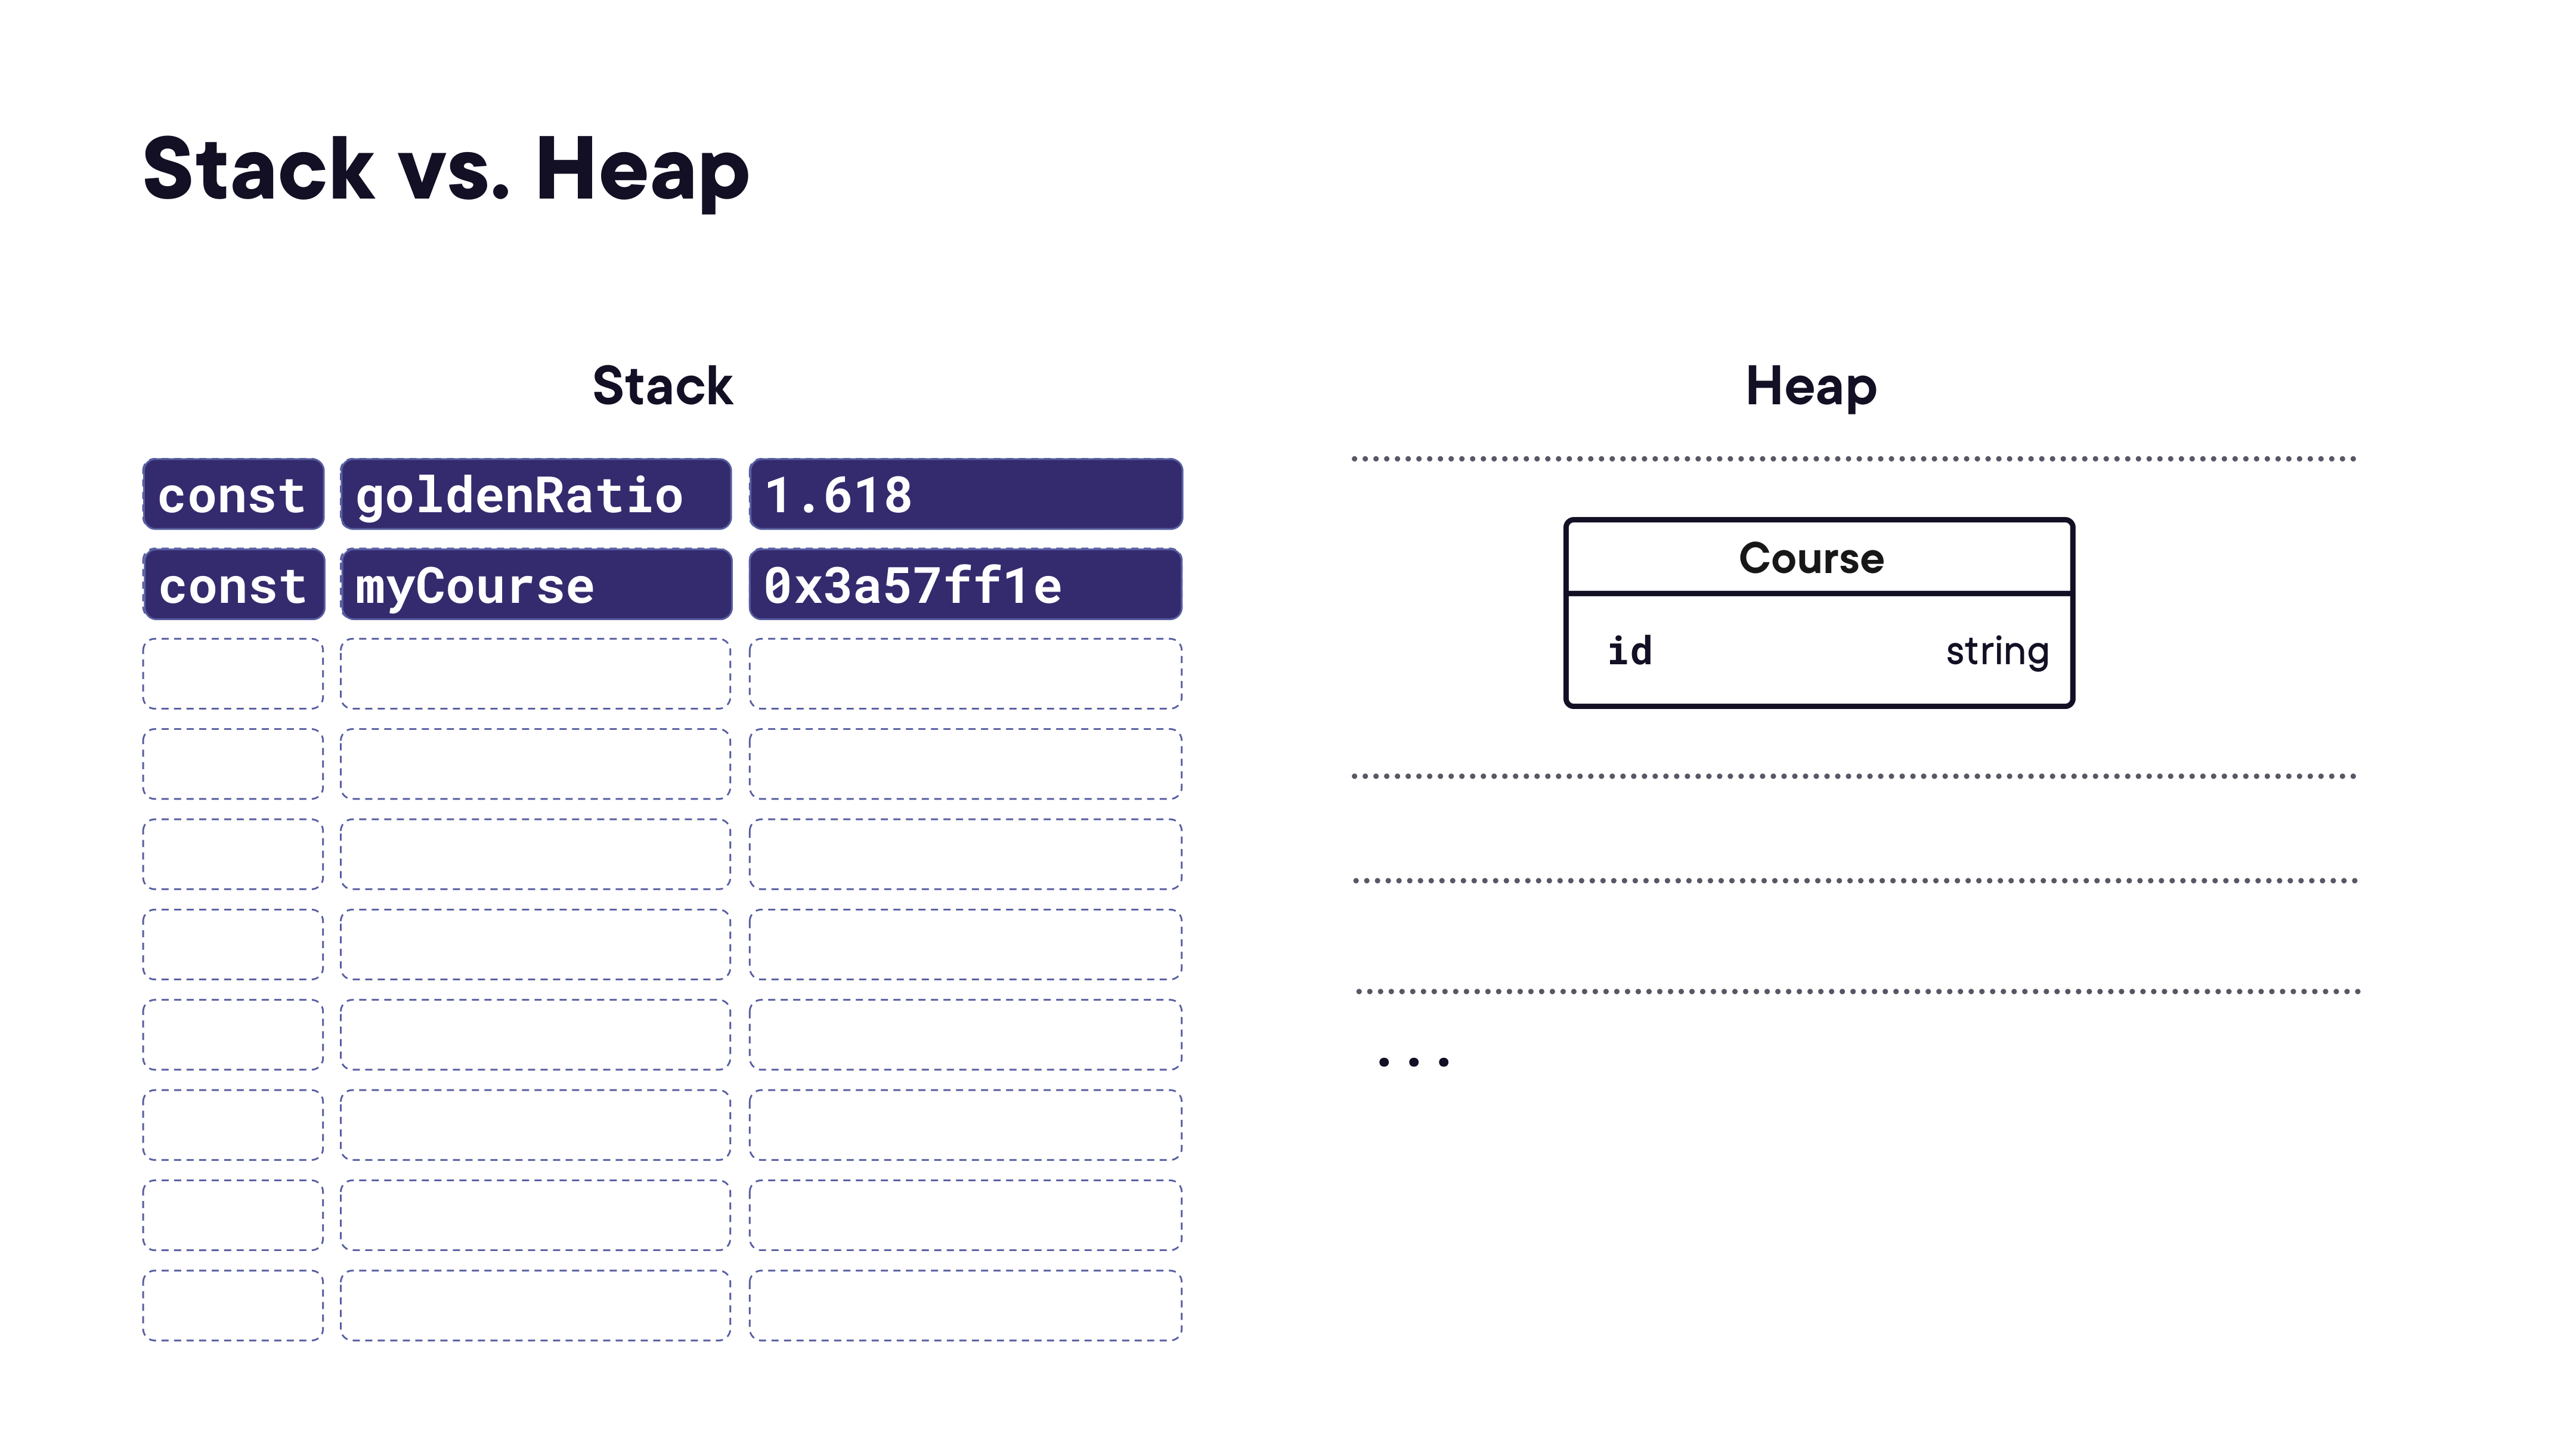

In [5]:
render_diagram(Path("assets/04-stack-vs-heap.png"))

**Primitive types** (number, boolean, string, etc.) are stored *directly on the stack* — the variable holds the value itself.

**Objects** are stored on the *heap* — the stack variable holds a memory address (e.g. `0x3a57ff1e`) that points to the object's actual data in the heap.



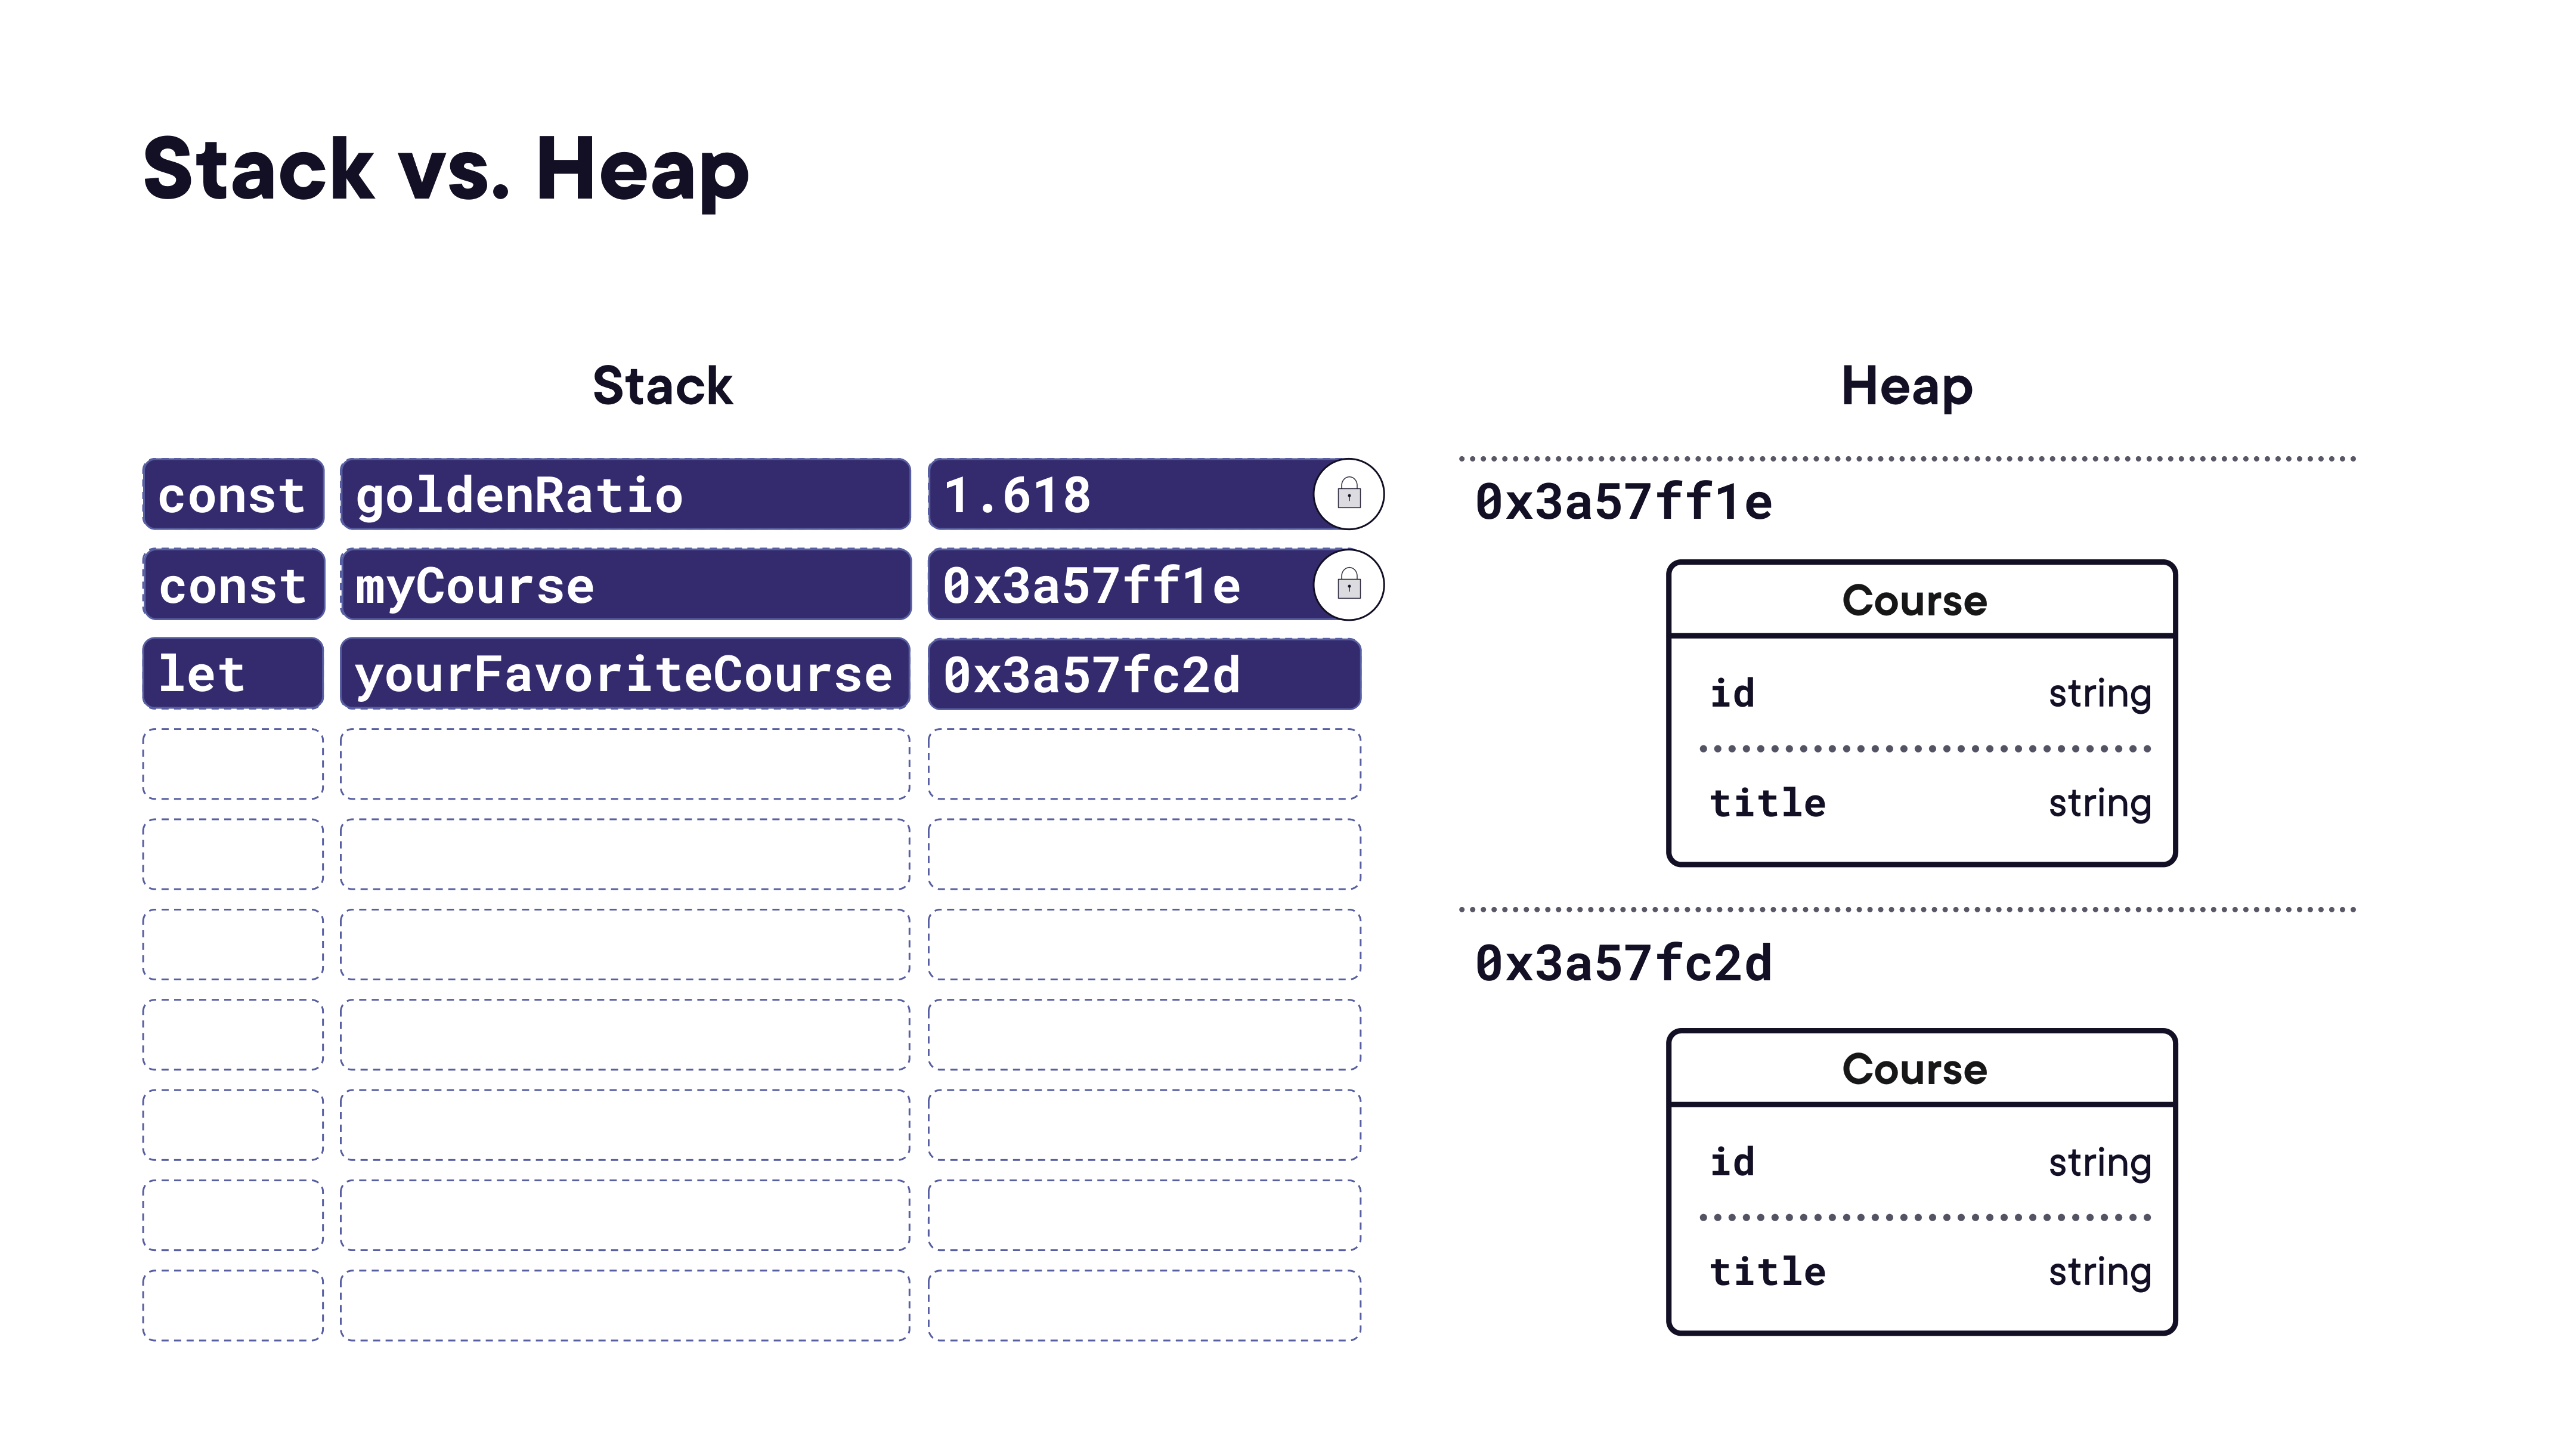

In [6]:
render_diagram(Path("assets/05-stack-heap-two-objects.png"))

Two variables pointing to *different* heap objects (`0x3a57ff1e` and `0x3a57fc2d`). Changing one does not affect the other. The `const` lock icon on `myCourse` and `goldenRatio` means those bindings cannot be reassigned, but the object at `0x3a57ff1e` can still be mutated.

```javascript
const myCourse = { id: "1", title: "Arrays" };   // → 0x3a57ff1e
let yourFavoriteCourse = { id: "2", title: "JS" }; // → 0x3a57fc2d

// If both pointed to the same address:
yourFavoriteCourse = myCourse;          // now both → 0x3a57ff1e
yourFavoriteCourse.title = "Edited Title"; // myCourse.title is ALSO "Edited Title"
```

### Comparing and Cloning Objects

Two challenges introduced by reference semantics:

**Comparing** — two object variables are equal only if they point to the *same* heap address:
```javascript
course1 === course2 // true only if both are the exact same object in memory
```

**Cloning** — copying an object requires deliberate effort.

#### Shallow Copy

Two approaches for copying properties one level deep:

```javascript
// Spread operator
const newObj = { ...oldObj };

// Object.assign
Object.assign(newObj, sourceObj);
```

Both produce a **shallow copy**: primitive properties are duplicated, but nested object properties still share the same heap reference.



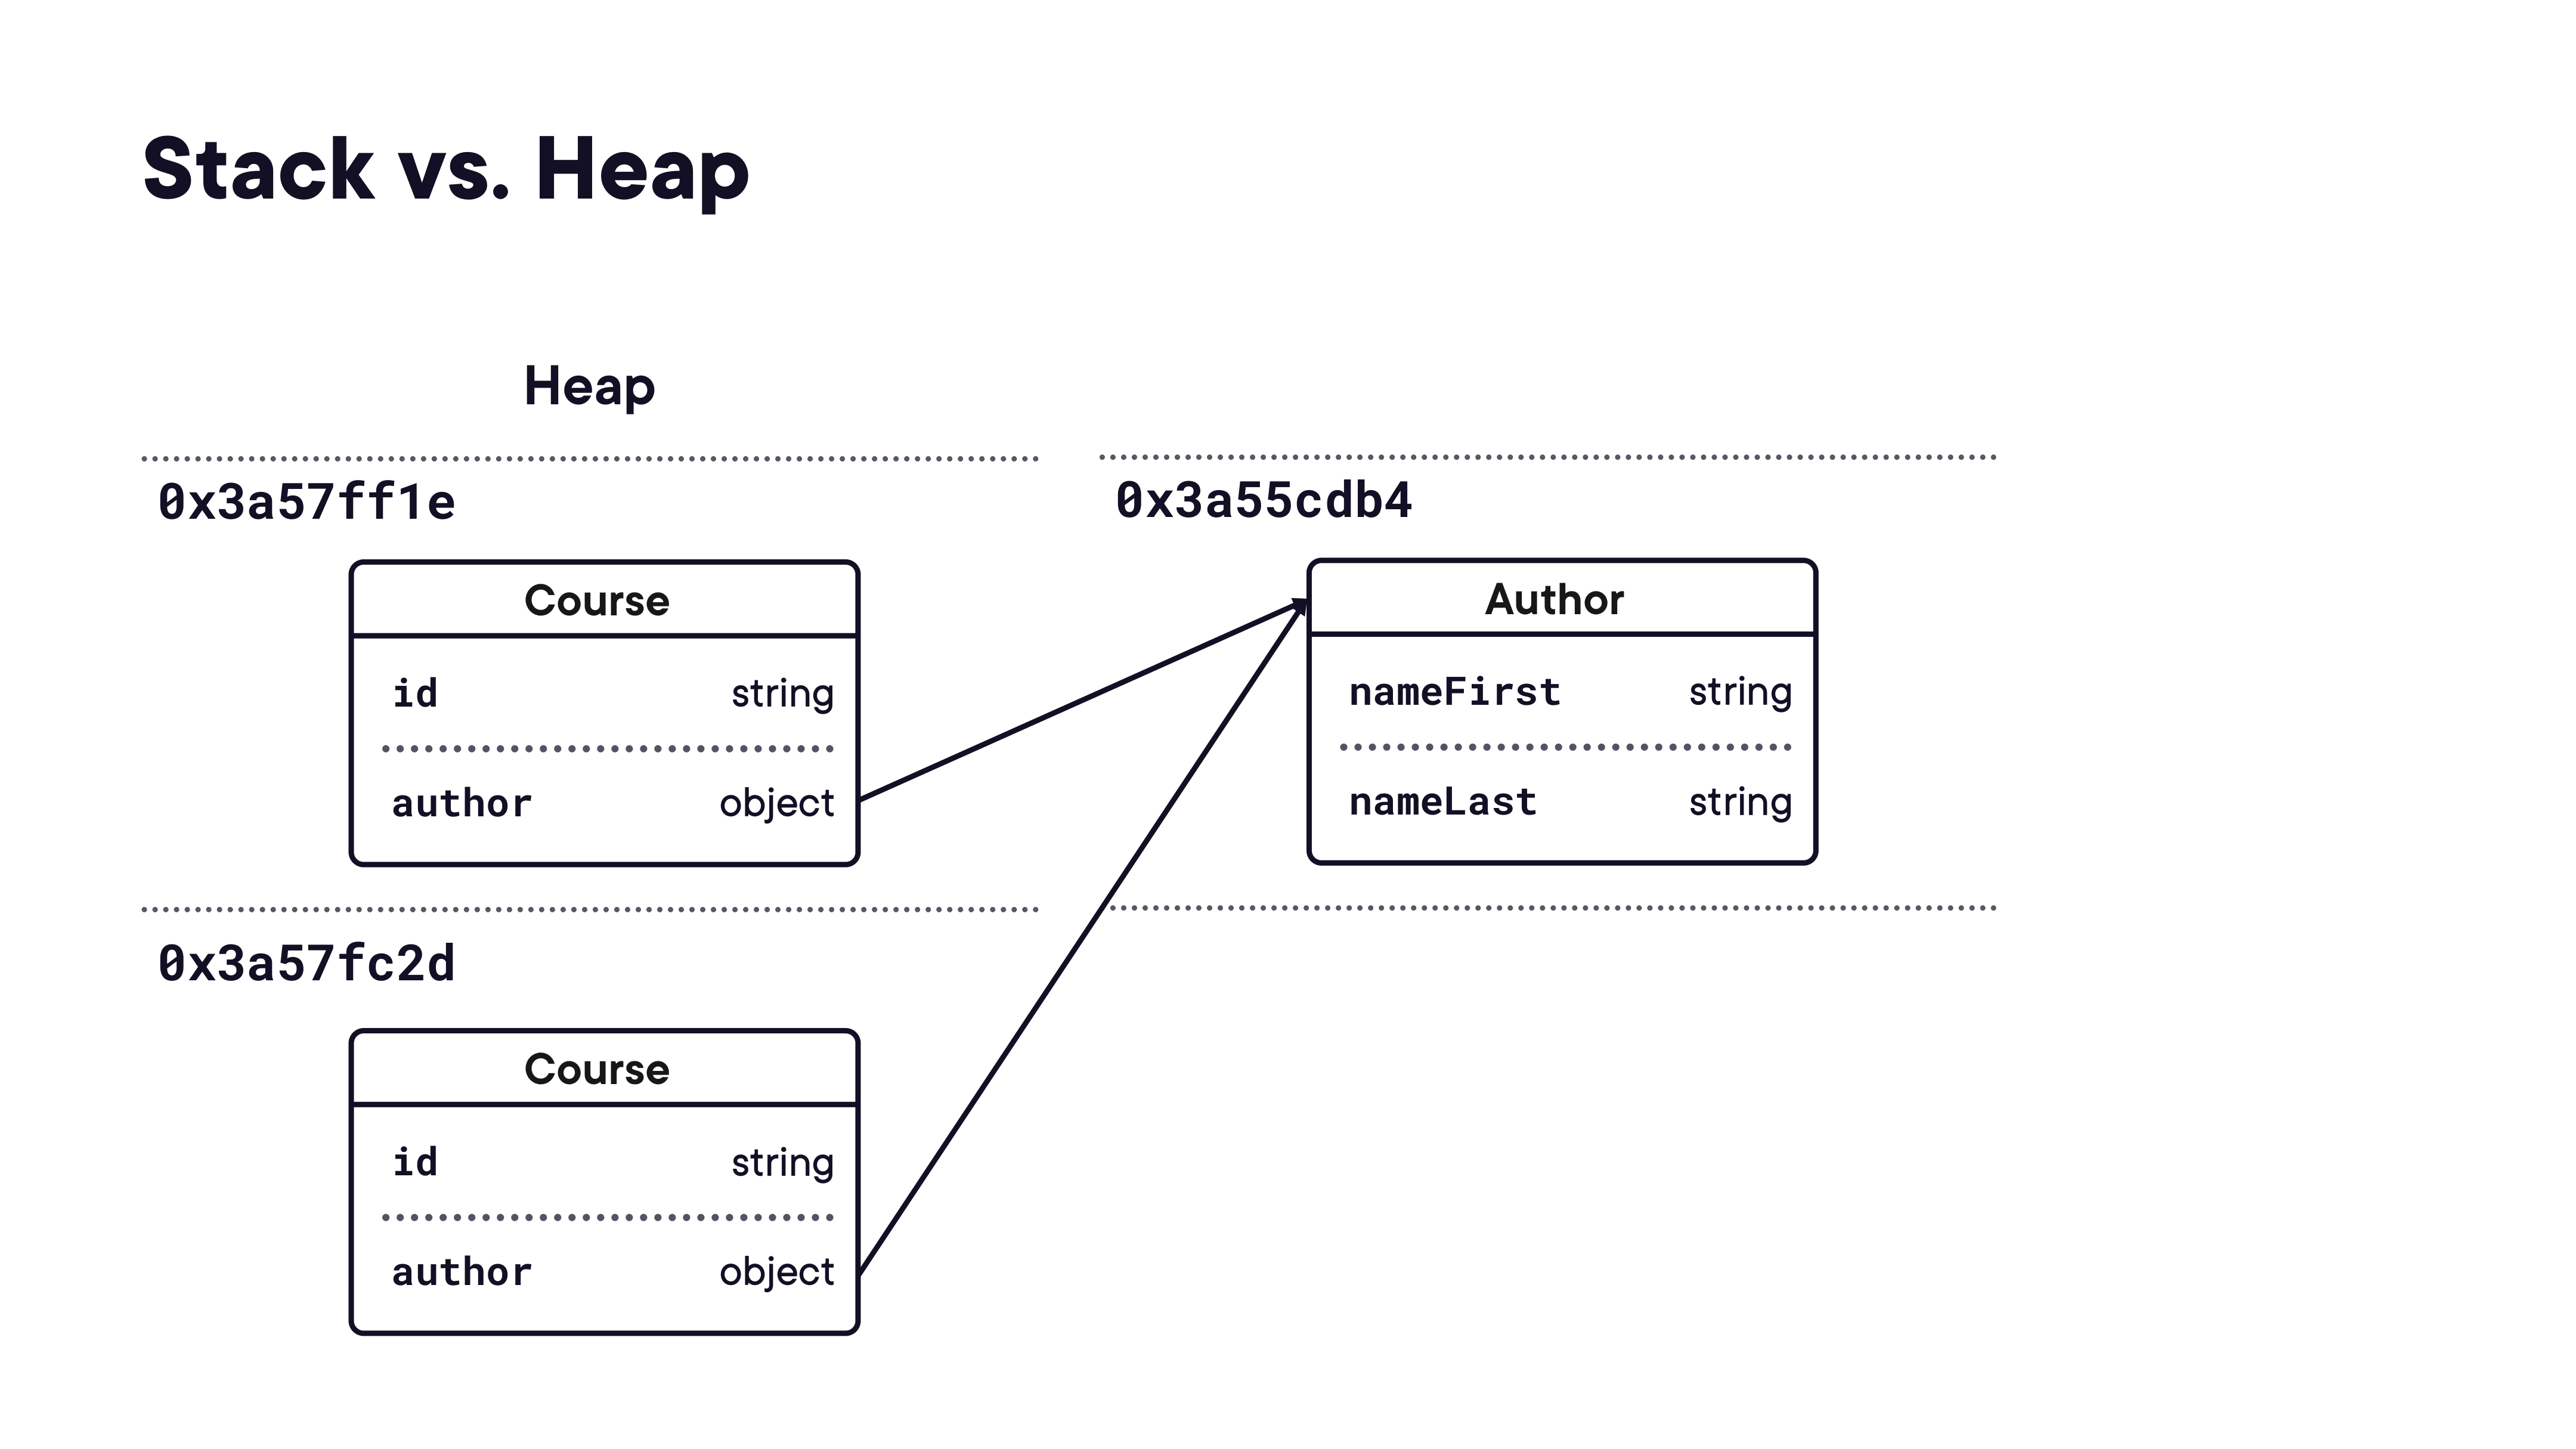

In [7]:
render_diagram(Path("assets/06-shallow-copy-shared-ref.png"))

After a shallow copy, `course1.author` and `course2.author` both point to the **same** `Author` object at `0x3a55cdb4`. Mutating `course2.author.nameFirst` also changes `course1.author.nameFirst`.

#### Deep Copy

A deep copy recursively duplicates every nested object and array, so no references are shared.



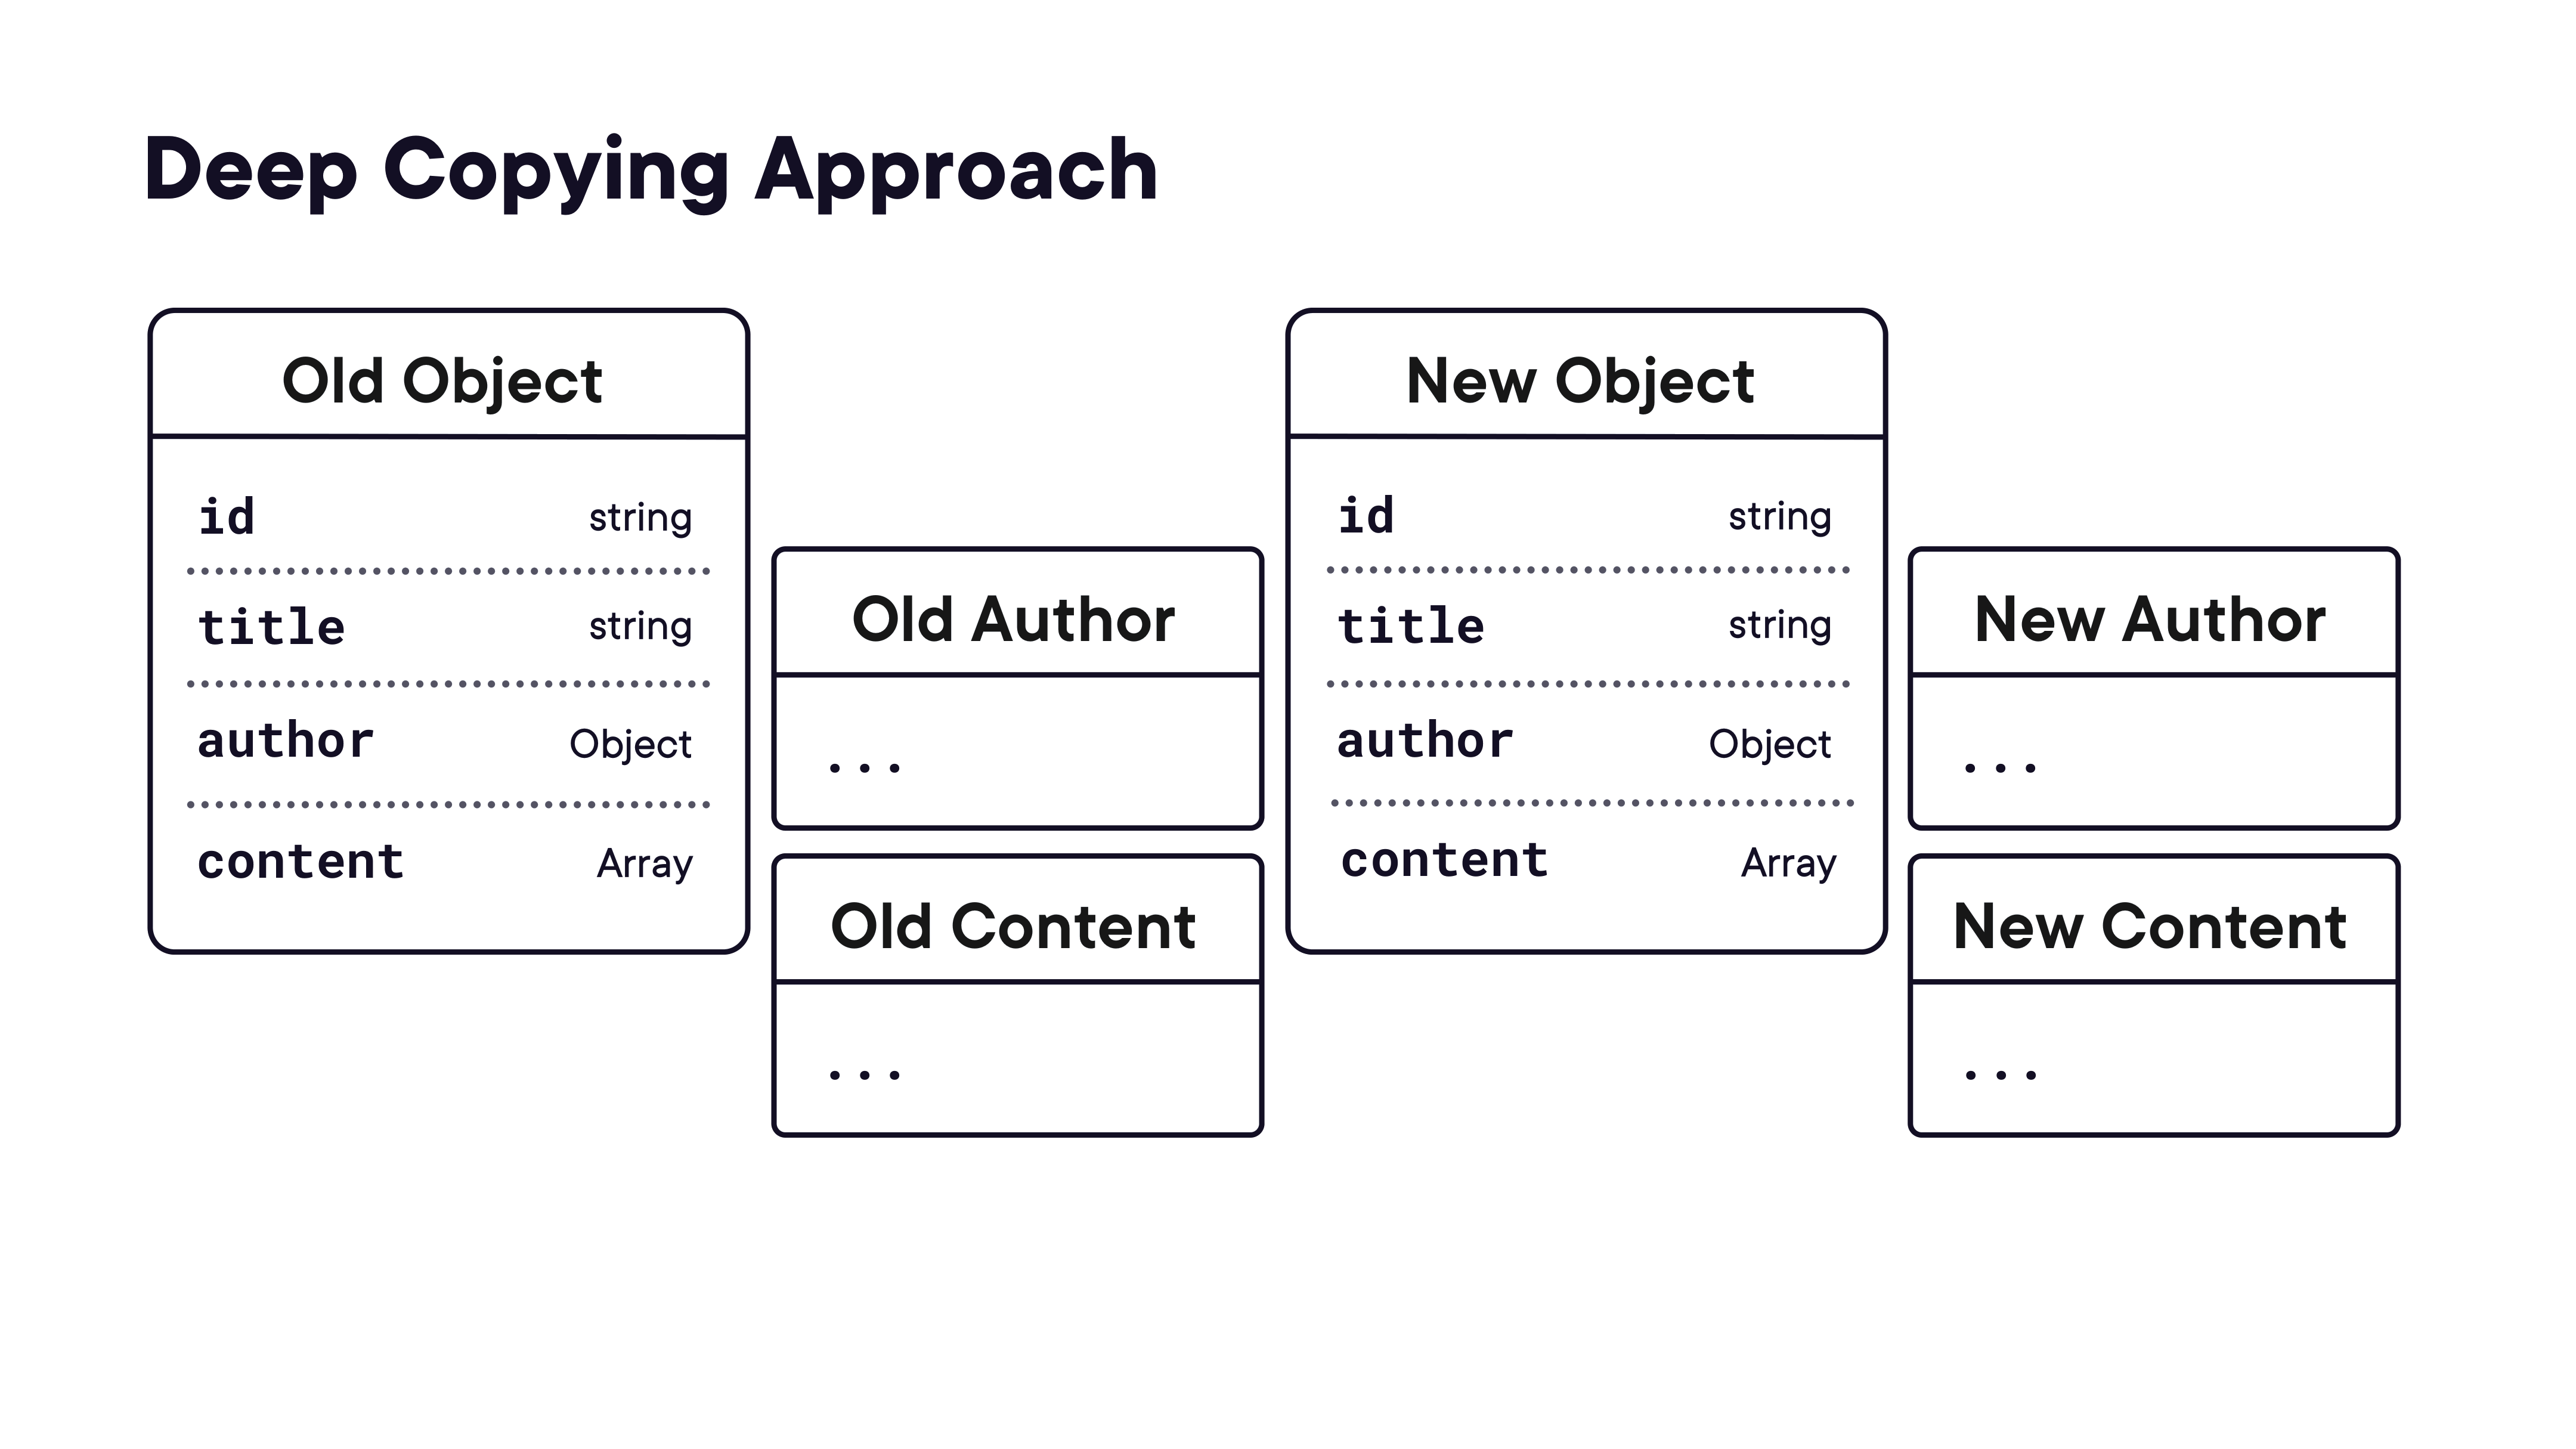

In [8]:
render_diagram(Path("assets/07-deep-copy-nested.png"))

Deep copy creates completely independent trees — Old Author and New Author are separate heap objects.

#### Deep Copy Techniques

**Option 1: `JSON.parse(JSON.stringify(original))`**

```javascript
const deepCopy = JSON.parse(JSON.stringify(original));
```

Works by serialising the object to a JSON string and parsing it back into a fresh object tree. Simple, but lossy:

| Value type | Behaviour |
|---|---|
| `string`, `number`, `boolean`, `null` | ✅ copied correctly |
| nested objects and arrays | ✅ fully independent copies |
| `undefined` (property value) | ❌ property is dropped entirely |
| `undefined` (array element) | ❌ converted to `null` |
| `function` | ❌ property is dropped entirely |
| `Date` | ❌ converted to an ISO string |
| `Map`, `Set` | ❌ converted to `{}` |
| `RegExp` | ❌ converted to `{}` |
| circular references | ❌ throws a `TypeError` |

**Option 2: `structuredClone(original)`** *(modern, preferred)*

```javascript
const deepCopy = structuredClone(original);
```

Built into browsers (since 2022) and Node.js (≥ 17). Uses the [Structured Clone Algorithm](https://developer.mozilla.org/en-US/docs/Web/API/Web_Workers_API/Structured_clone_algorithm) — the same mechanism used internally for `postMessage` and `IndexedDB`.

| Value type | Behaviour |
|---|---|
| `string`, `number`, `boolean`, `null`, `undefined` | ✅ copied correctly |
| nested objects and arrays | ✅ fully independent copies |
| `Date` | ✅ cloned as a `Date` (not a string) |
| `Map`, `Set` | ✅ cloned with correct type |
| `RegExp` | ✅ cloned as a `RegExp` |
| `ArrayBuffer`, `TypedArray`, `Blob`, `File` | ✅ cloned correctly |
| circular references | ✅ handled correctly |
| `function` | ❌ throws a `DataCloneError` |
| DOM nodes | ❌ throws a `DataCloneError` |
| class instances with methods | ⚠️ data is cloned but prototype chain is lost — result is a plain object |

```javascript
const original = {
  title: "JS Course",
  publishedAt: new Date("2024-01-01"),
  tags: new Set(["javascript", "arrays"]),
  author: { name: "Alice", scores: [95, 88, 72] }
};

const copy = structuredClone(original);

copy.author.name = "Bob";
copy.author.scores.push(100);
copy.tags.add("objects");

console.log(original.author.name);    // "Alice"  ← unaffected
console.log(original.author.scores);  // [95, 88, 72]  ← unaffected
console.log(original.publishedAt);    // Date object — still intact
console.log(original.tags.size);      // 2  ← unaffected
```

**Which to use:**

| Scenario | Recommendation |
|---|---|
| Simple objects with only primitives | `JSON.parse(JSON.stringify(...))` — widely supported, zero dependencies |
| Objects with `Date`, `Map`, `Set`, circular refs | `structuredClone()` — correct and concise |
| Objects with class methods you need preserved | Write a custom clone function or use a library |

### Functions as Properties

Functions can be stored as object properties (methods). Two equivalent syntaxes:

```javascript
// Traditional (pre-ES6)
const course = {
  bookmark: function() { /* ... */ }
};

// Shorthand method syntax (ES6+) — preferred
const course = {
  bookmark() { /* ... */ }
};
```

### Scope in Objects — `this` and Parameters

#### Passing Primitives to Functions

Primitives are **passed by value** — the function receives a copy; changes inside the function don't affect the caller's variable:

```javascript
let boolean = false;
function toggle(b) {
  b = true;         // modifies the local copy only
}
toggle(boolean);
console.log(boolean); // still false
```

#### Passing Objects to Functions

Objects are **passed by reference** — the function receives the same heap pointer. Mutating a property through that pointer *does* affect the caller:

```javascript
const contentBlock = { title: "Original" };
function editTitle(block) {
  block.title = "EDITED"; // same heap object
}
editTitle(contentBlock);
console.log(contentBlock.title); // "EDITED"
```

But *reassigning* the parameter variable inside the function only changes the local pointer — it does not change the caller's variable:

```javascript
function replace(block) {
  block = { title: "EDITED" }; // local rebind only; caller is unaffected
}
```

### Object Wrappers of Primitives

Primitives are not objects — yet you can call methods on them:

```javascript
let number = 45.8256;
number.toFixed(2); // "45.83"
```

JavaScript temporarily wraps the primitive in its corresponding object type (`Number`, `String`, `Boolean`) for the duration of the method call, then discards the wrapper:

```javascript
// What JavaScript does behind the scenes:
// 1. Wrap:   new Number(45.8256)
// 2. Call:   .toFixed(2)
// 3. Discard the wrapper
```

> **Primitive wrappers** are a convenient way to get object-like functionality on primitives without needing to instantiate an object yourself.


## Module 04: Arrays

_How arrays work as objects, five ways to create them, identification, element access, slicing, combining, cloning, sorting, sparse arrays, and alternative collection types._

### Arrays are Objects

Arrays share the same foundations as objects but differ in key ways:

**Ways arrays are like objects:**
- Arrays contain properties
- Access properties with bracket notation
- Array functions come from `Array.prototype`
- Can be created in many of the same ways as objects

**Ways arrays differ from objects:**

| | Objects | Arrays |
|---|---|---|
| Keys | Any string | Zero-based numbers only |
| Access | Dot or bracket notation | Bracket notation only |
| Methods | `Object.prototype` | `Array.prototype` (additional methods) |

### Course Data Model

A real-world example: a `Course` object holds an array of `ContentBlock` items.



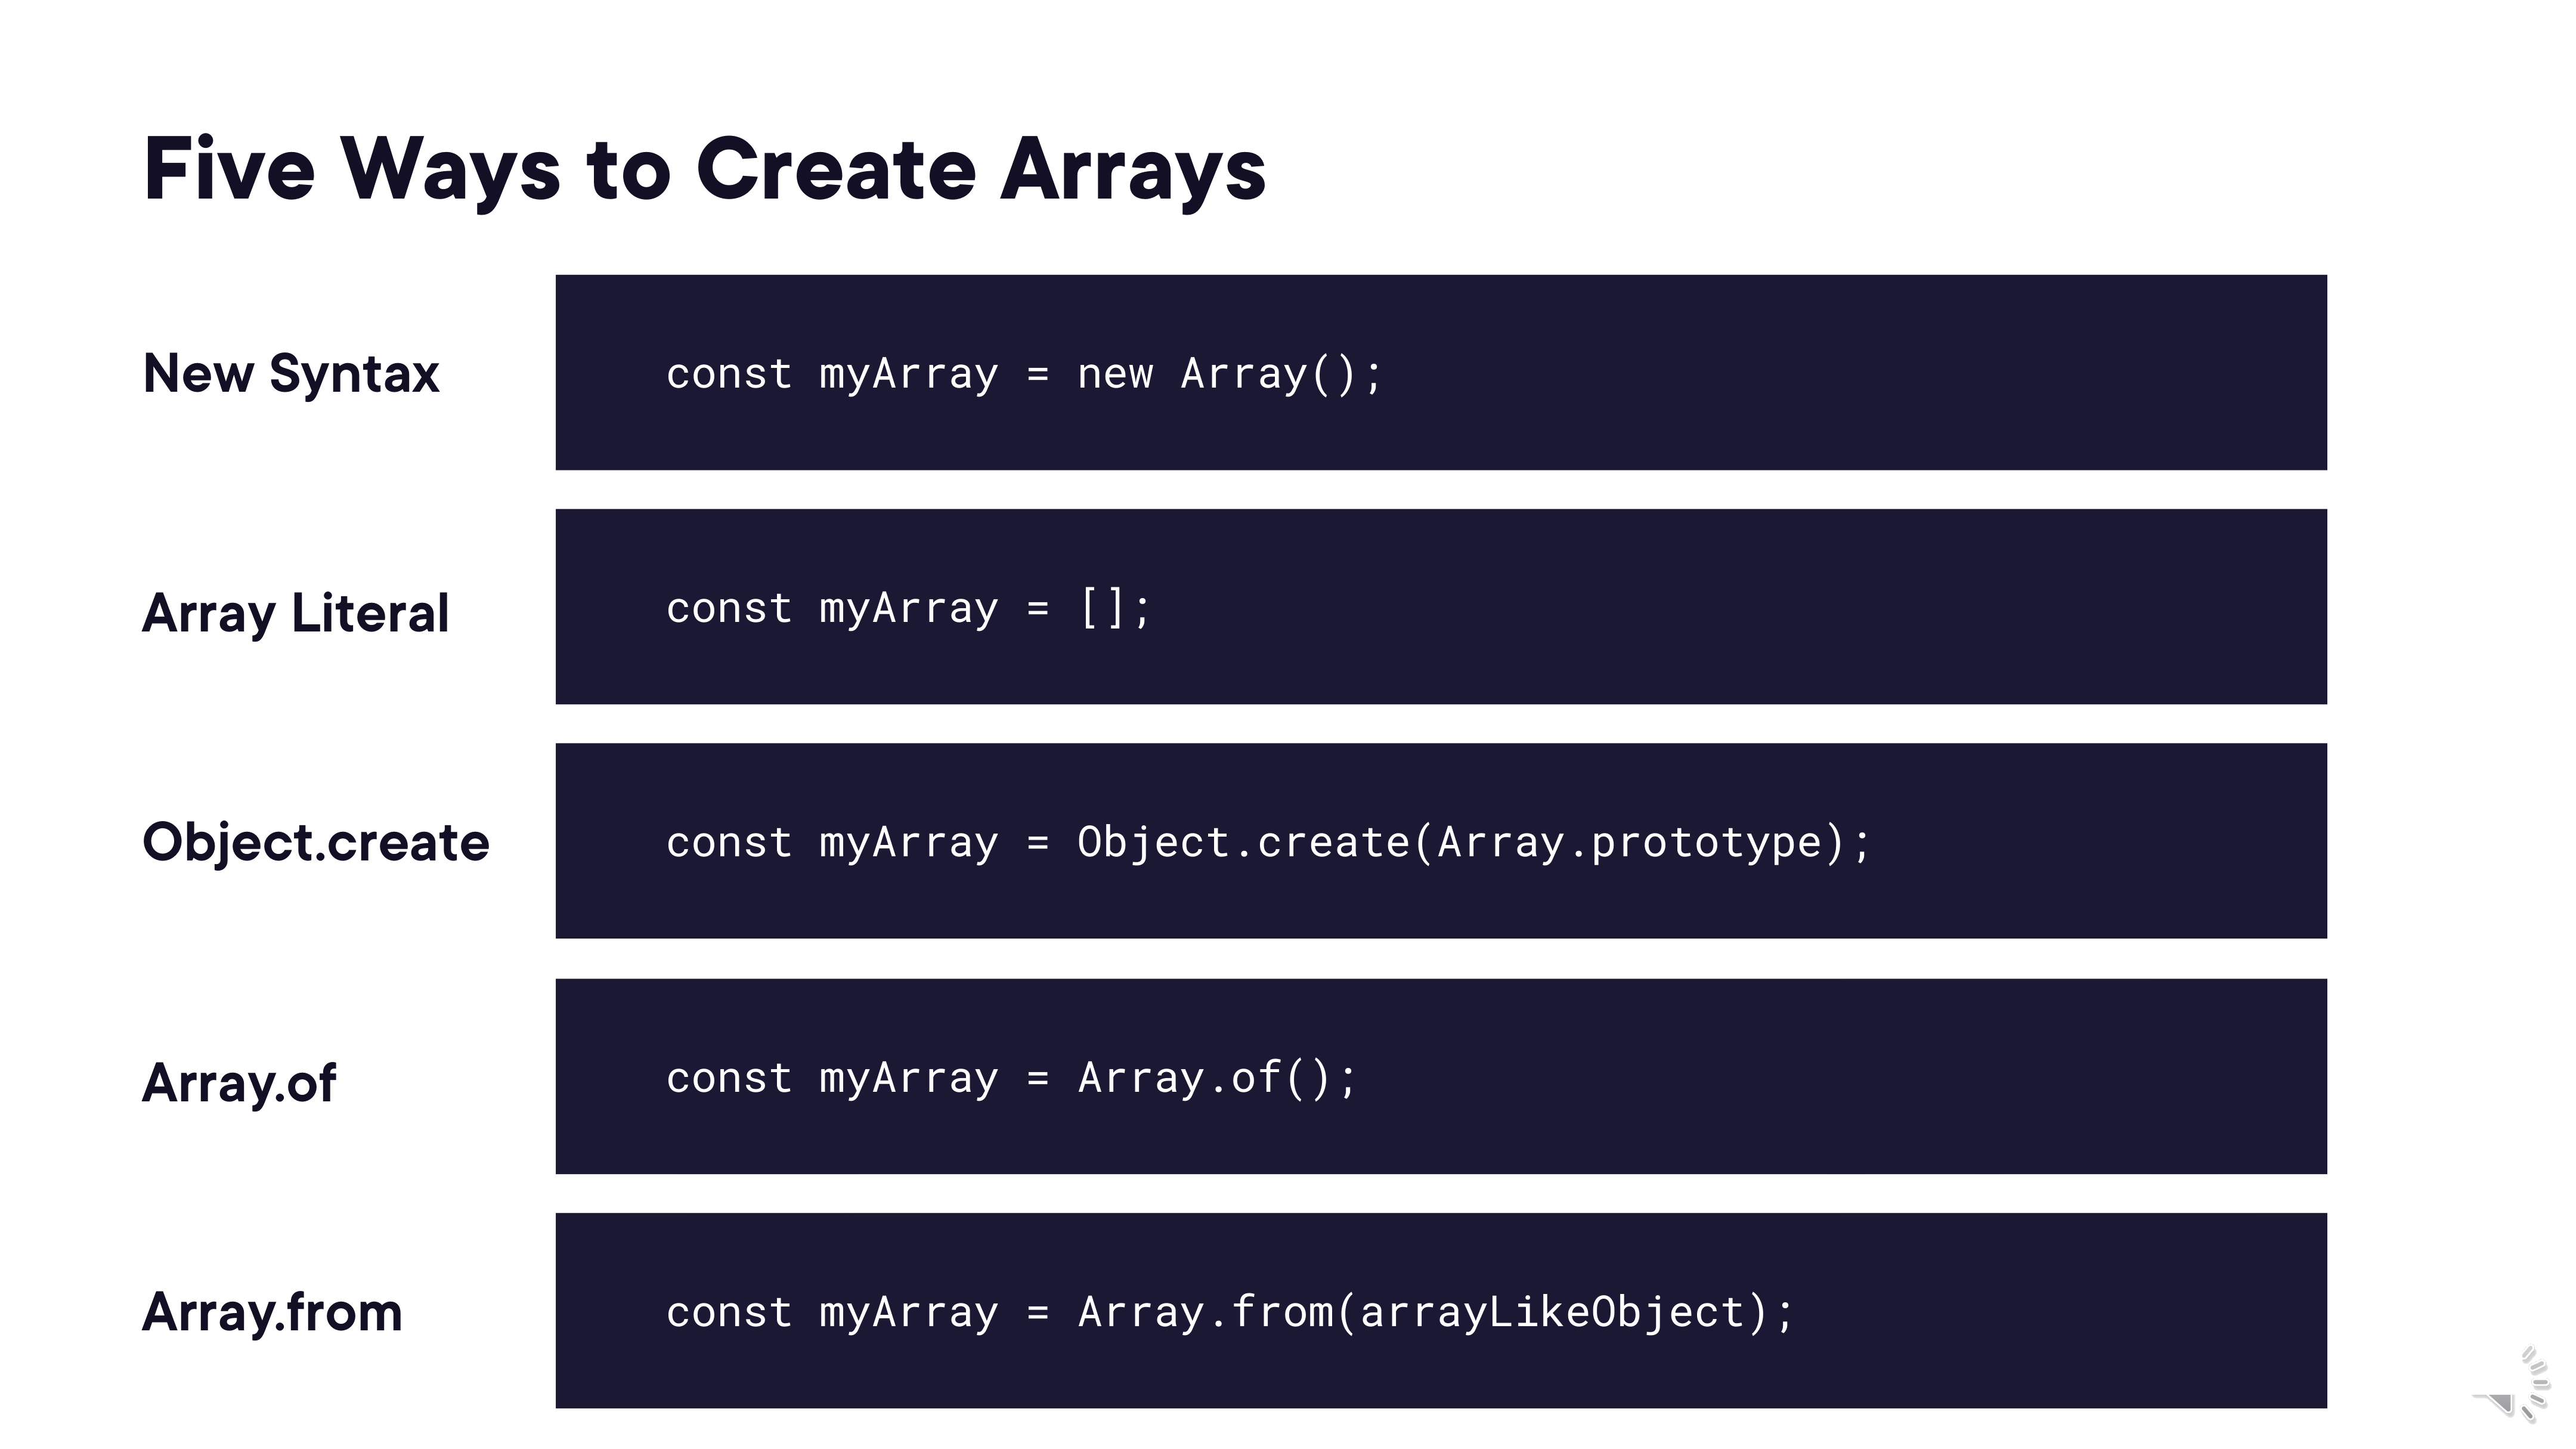

In [9]:
render_diagram(Path("assets/08-course-object-structure.png"))

### Creating Arrays

Five ways to create arrays:

```javascript
// 1. Array literal — most common
const myArray = [];

// 2. new syntax
const myArray = new Array();

// 3. Object.create
const myArray = Object.create(Array.prototype);

// 4. Array.of — creates from arguments (avoids the single-number trap)
const myArray = Array.of(1, 2, 3);     // [1, 2, 3]

// 5. Array.from — creates from any iterable or array-like object
const myArray = Array.from(arrayLikeObject);
```

**The `new Array` single-number trap:**

```javascript
new Array(2, 3, 4); // → [2, 3, 4]  (3 elements)
new Array(4);       // → [ , , , ]  (4 empty slots — sparse!)
```

Passing a single number to `Array` creates a sparse array of that *length* — not an array containing that number. Use `Array.of(4)` to get `[4]`.

**Array-like objects** — objects that are iterable but do not link to `Array.prototype` (e.g. `NodeList`, `arguments`, `Set`). Convert them with `Array.from`.

### Identifying Arrays

All arrays ultimately link to `Object.prototype`, so `typeof []` returns `"object"`. Use these to check specifically for arrays:

```javascript
myArray instanceof Array           // true if Array is in the prototype chain
Array.isArray(myArray)             // true if myArray is an Array (most reliable)
Array.prototype.isPrototypeOf(myArray) // true if Array.prototype is in chain
```

`Array.isArray` is preferred — it works across iframes/realms where `instanceof` can fail.

### Adding and Accessing Array Elements

Arrays use **zero-based** numeric indexes. The last index is always `array.length - 1`.

```javascript
const arr = ["a", "b", "c"];
arr[0];   // "a"
arr[2];   // "c"
arr.length; // 3
```

**Stacks (LIFO — Last In, First Out)** — add/remove from the end:

```javascript
arr.push("d");  // add to end   → ["a","b","c","d"]
arr.pop();      // remove from end → returns "d"
```

**Queues (FIFO — First In, First Out)** — add to end, remove from front:

```javascript
arr.push("d");  // add to end
arr.shift();    // remove from front → returns "a"
```

**`unshift`** — add to the front (shifts all existing elements right):

```javascript
arr.unshift("z"); // → ["z","a","b","c"]
```



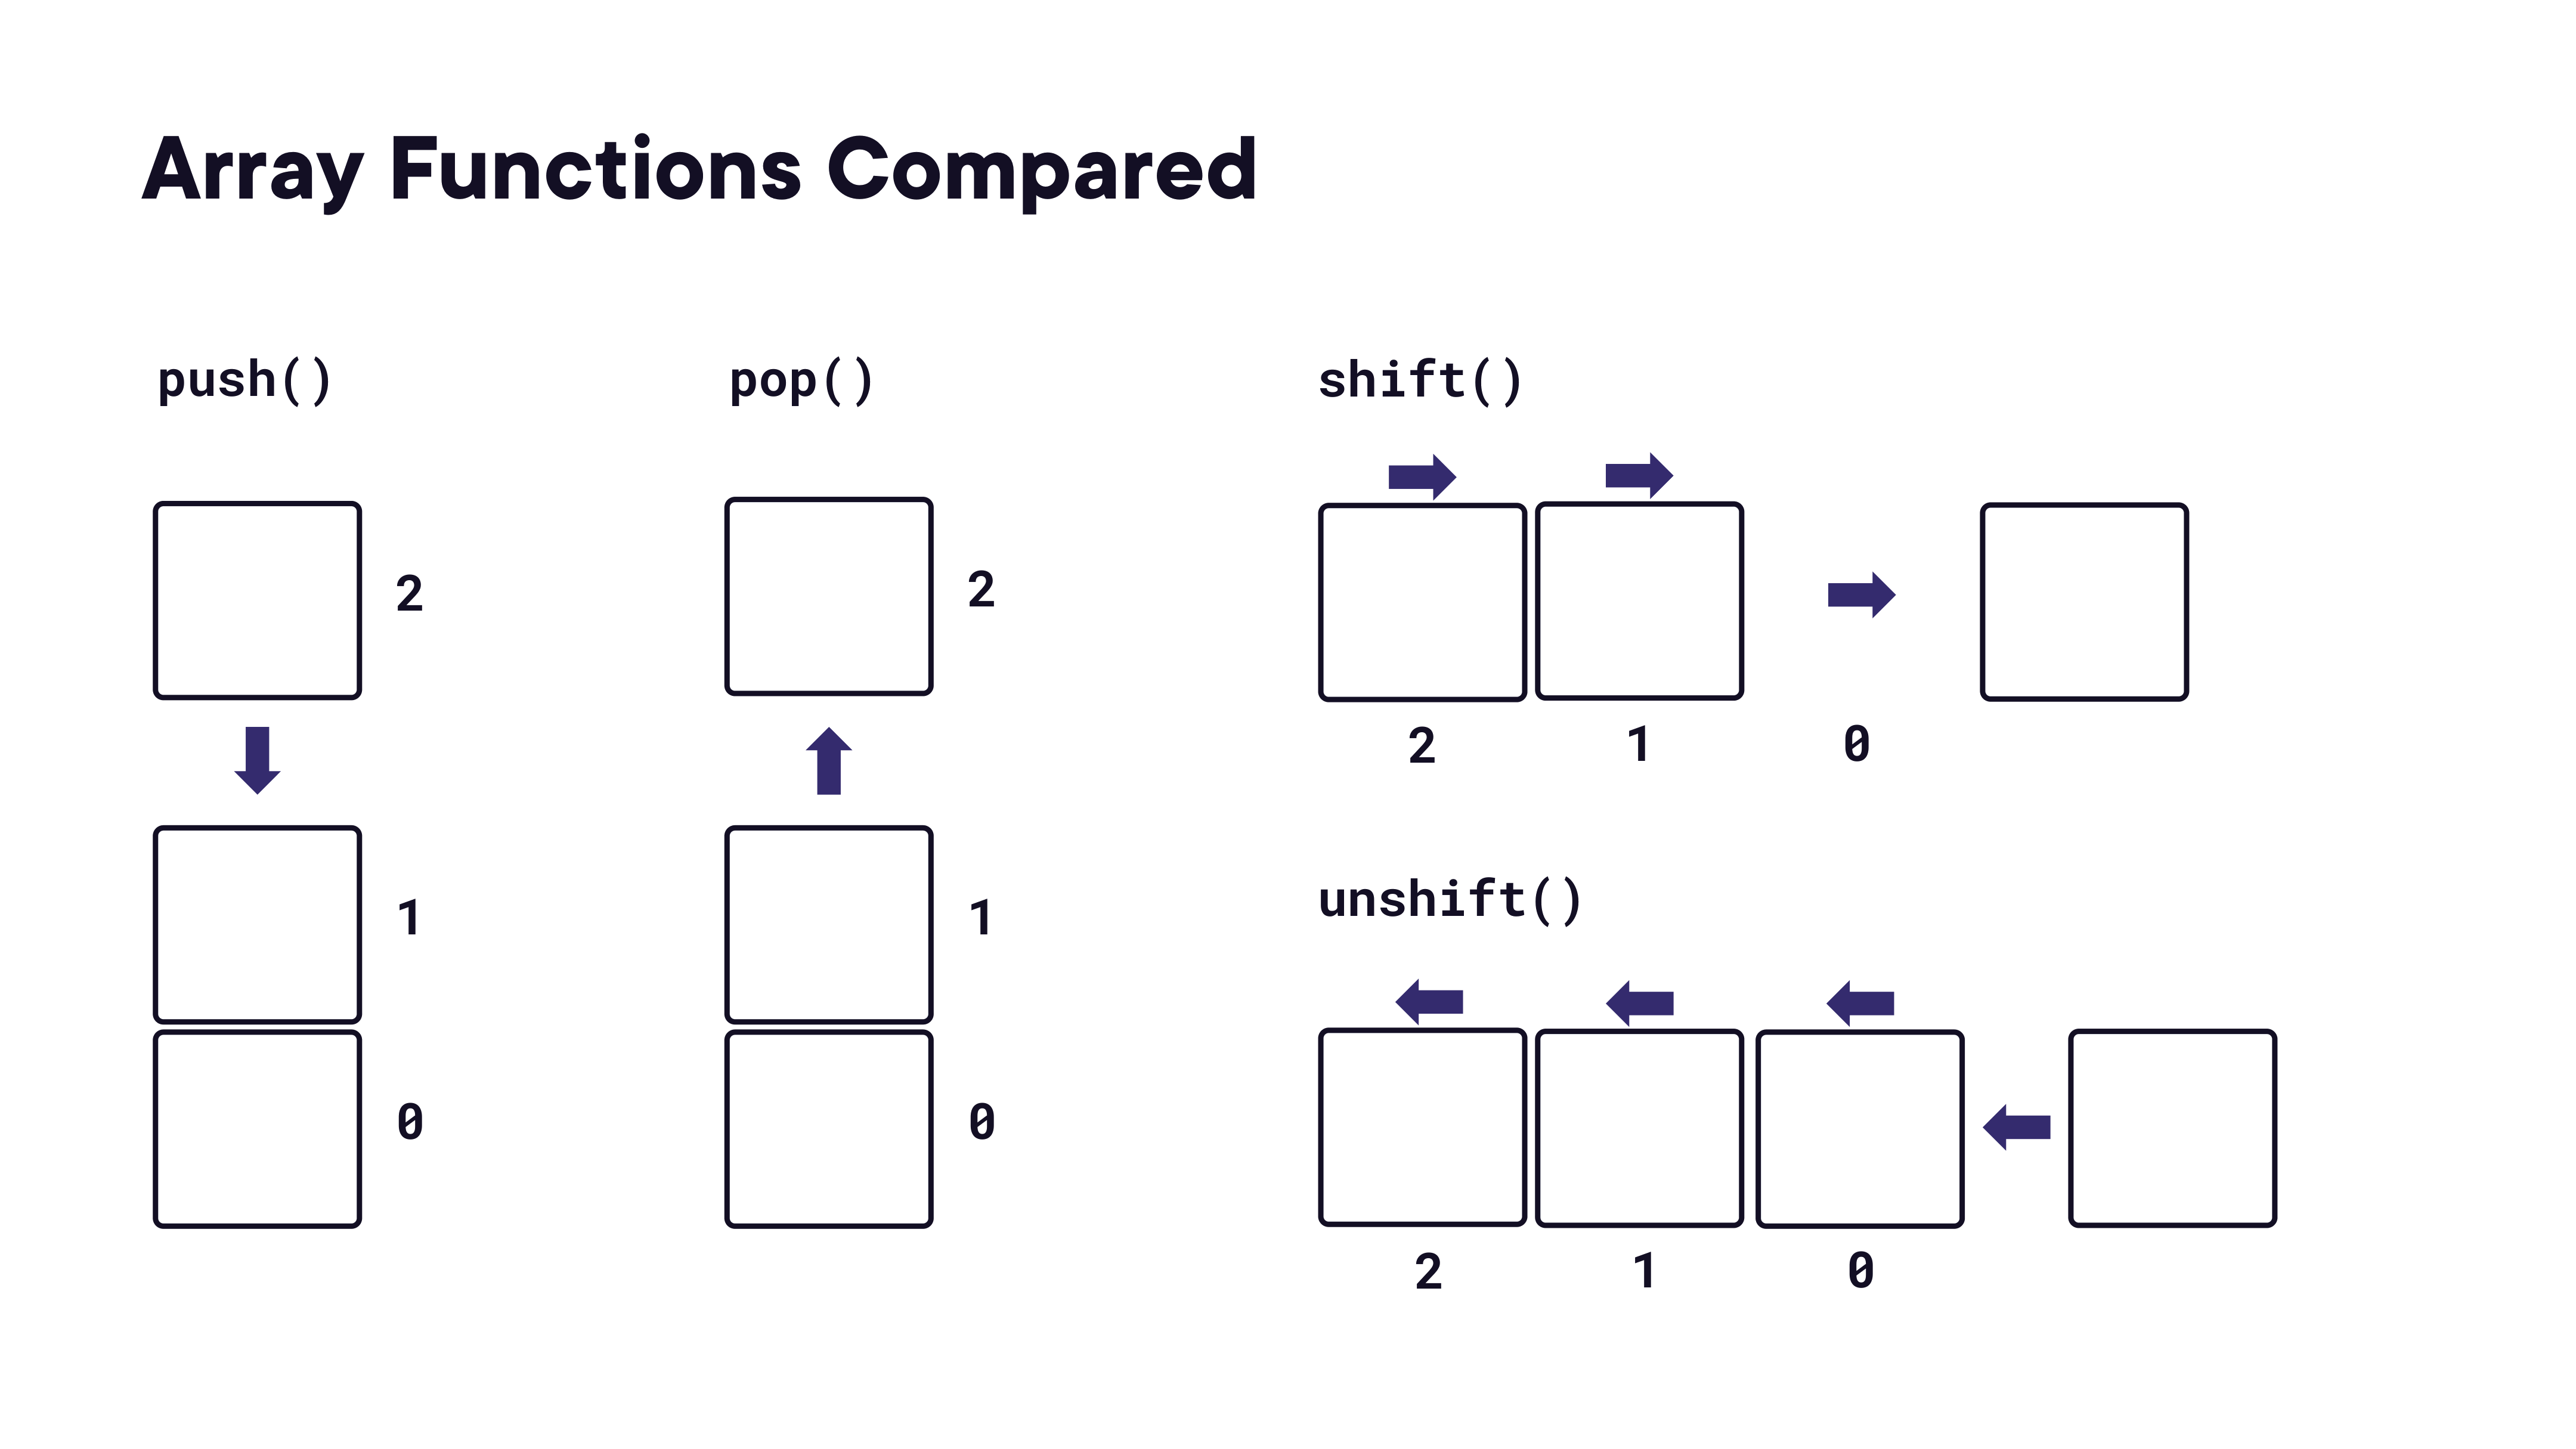

In [10]:
render_diagram(Path("assets/09-array-functions-compared.png"))

### Cutting Up Arrays

Removing an element with `delete` leaves a **blank slot** (sparse array) — avoid it.

Use `splice` or `slice` instead:

```javascript
// splice — DESTRUCTIVE: modifies the original array, returns removed elements
const removed = myArray.splice(startIndex, deleteCount);
// Non-destructive alternative (ES2023):
const newArray = myArray.toSpliced(startIndex, deleteCount);

// slice — NON-DESTRUCTIVE: returns a new array, original is unchanged
const piece = myArray.slice(2, 4); // elements at index 2 and 3
```

| | `splice` | `slice` |
|---|---|---|
| Mutates original | ✓ (destructive) | ✗ |
| Returns | Removed elements | New sub-array |
| Non-destructive version | `toSpliced` | — |

### Combining Arrays

```javascript
// concat — returns a new combined array
const combined = array1.concat(array2);

// Spread operator — flattens arrays before combining
const combined = [...array1, ...array2];
```

**The spread operator vs. concat gotcha:**
```javascript
// concat with an array argument creates a nested array:
[1, 2].concat([3, 4]);      // [1, 2, 3, 4]  ← correct
[1, 2].concat([[3, 4]]);    // [1, 2, [3, 4]] ← nested!

// spread always unpacks:
[...[1, 2], ...[3, 4]];     // [1, 2, 3, 4]
```

### Cloning Arrays

Arrays are objects, so they are reference types. A shallow clone shares references to nested objects:

```javascript
const clone = [...original];     // spread — shallow
const clone = original.slice();  // slice — shallow
```

For a **deep clone** of arrays containing objects, use `JSON.parse(JSON.stringify(original))` or `structuredClone(original)`.

### Sorting Arrays

```javascript
// reverse — DESTRUCTIVE
array.reverse();
// Non-destructive version:
array.toReversed();

// sort with a comparison function — DESTRUCTIVE
array.sort((a, b) => {
  if (a.title > b.title) return 1;   // a comes after b
  if (b.title > a.title) return -1;  // b comes after a
  return 0;                           // equal
});
// Non-destructive version:
array.toSorted(comparisonFn);
```

The comparison function receives two elements `a` and `b`:
- Return `+1` → `a` sorts higher (after `b`)
- Return `-1` → `b` sorts higher (after `a`)
- Return `0` → order is unchanged

### Sparse Arrays

A **sparse array** has blank slots — indexes that contain `undefined` but don't actually exist as properties.

Ways to create a sparse array:
```javascript
// Initialising with length but not filling
const arr = new Array(4);       // [ , , , ]

// Deleting an element
delete arr[2];                  // blank slot at index 2

// Adding beyond current length
const fruits = ["apple", "banana"];
fruits[5] = "cherry";           // indices 2, 3, 4 are blank slots
```

**Sparse arrays are handled inconsistently** across iteration methods:
- `forEach`, `map`, `filter` — **skip** blank slots (treat them as non-existent)
- `for` loop, `for...of` — **visit** blank slots as `undefined`

**Best practice:** keep arrays dense and homogeneous — all elements the same type, no gaps.

### Maps, Sets, and Typed Arrays

JavaScript provides specialised collection types:

| | Arrays | Maps | Sets | Typed Arrays |
|---|---|---|---|---|
| Comprised of | keys + values | keys + values | values only | keys + values |
| Ordered by | — | insertion order | insertion order | — |
| Keys are | zero-indexed numbers | anything | n/a | zero-indexed numbers |
| Values are | anything | anything | unique values | specified type only |

**Typed Arrays** — for numeric data of a specific bit width:
`Int8Array`, `Uint8Array`, `Uint8ClampedArray`, `Int16Array`, `Uint16Array`, `Int32Array`, `Uint32Array`, `Float32Array`, `Float64Array`, `BigInt64Array`, `BigUint64Array`

Used for performance-critical numeric work (WebGL, audio processing, binary protocols).


## Module 05: Array Iteration Deep Dive

_Detailed comparison of all loop forms, then the higher-order iteration methods: summarising (`reduce`, `join`, `some`, `every`), searching (`find`, `filter`, `includes`), and transforming (`map`)._

### For Loops

**Classic `for` loop** — works but verbose:
```javascript
for (let i = 0; i < array.length; i++) {
  // use array[i]
}
```

The last valid index is `array.length - 1`. Common control-flow tools:
```javascript
if (elementIsFound) { break; }        // stop iterating
if (elementIsIrrelevant) { continue; } // skip to next
```

**Drawbacks:**
- Lots of boilerplate (`let i = 0; i < length; i++`)
- Easy off-by-one errors (`<` vs `<=`)
- Difficult to read

**Improved loop forms:**
```javascript
// for...of — iterates values of any iterable (arrays, strings, Set, Map, etc.)
for (let element of array) { /* ... */ }

// for...in — iterates enumerable property KEYS (use for objects, not arrays)
for (let property in object) { /* ... */ }
```

### Comparison of JavaScript For Loops

| | `for` | `for...in` | `for...of` | `forEach` |
|---|---|---|---|---|
| Iterates through | An index | Enumerable properties | Iterable objects | Array elements |
| Sparse array handling | No handling | No handling | No handling | Ignores `undefined` |
| `continue` and `break`? | ✓ | ✓ | ✓ | ✗ |

> `forEach` is clearly the best way to loop through an array… but there's usually a better option (one of the higher-order methods below).

### Summarising Arrays

Functions for summarising:

```javascript
// join — concatenates all elements into a string
["a", "b", "c"].join(", "); // "a, b, c"

// some — true if at least one element passes the test
array.some(el => el.price > 10);

// every — true if ALL elements pass the test
array.every(el => el.price > 0);

// reduce — accumulates a single value from left to right
const total = cart.products.reduce((accumulator, product) => {
  return accumulator + product.price;
}, 0); // 0 is the initial accumulator value

// reduceRight — same as reduce but iterates right to left
array.reduceRight((acc, el) => acc + el, 0);
```

**How `reduce` works:**

```
Step 1: acc = 0,    el = { price: 3.5  }  → acc = 3.5
Step 2: acc = 3.5,  el = { price: 5.99 }  → acc = 9.49
Step 3: acc = 9.49, el = { price: 4.2  }  → acc = 13.69
```

The final accumulator value (`13.69`) is the return value.

### Searching Through Arrays

```javascript
// includes — true if value is present (uses strict equality)
array.includes("banana");

// find — returns the FIRST matching element (or undefined)
const firstBookmarked = content.find(block => block.bookmarked === true);

// findIndex — returns the index of the first match (or -1)
const idx = content.findIndex(block => block.bookmarked === true);

// findLastIndex — index of the LAST match (or -1)
const lastIdx = content.findLastIndex(block => block.bookmarked === true);

// filter — returns a NEW array of ALL matching elements (shallow copy of matches)
const bookmarked = content.filter(block => block.bookmarked === true);
```

**`find` vs `filter`:**
- `find` → one element or `undefined`
- `filter` → new array of zero or more elements

### Map and Functional JavaScript

`map` transforms each element of an array into a new value, returning a new array of the same length:

```javascript
const prices = products.map(product => product.price);
// [3.5, 5.99, 4.2]

const discounted = products.map(product => ({
  ...product,
  price: product.price * 0.9
}));
```

### Comparison of JavaScript Array Functions

| Function | Called on | Argument | Returns |
|---|---|---|---|
| `forEach` | array | function | none |
| `filter` | array | function | array |
| `sort` | array | function | array |
| `some` | array | function | boolean |
| `every` | array | function | boolean |
| `reduce` | array | function | any |
| `map` | array | function | array |

All higher-order array functions accept a **callback function** as their argument. `map`, `filter`, and `sort` return a new array; `reduce` returns any accumulated value; `some`/`every` return booleans; `forEach` returns nothing.


### Course Summary — Domain Model

The data model used throughout this course:



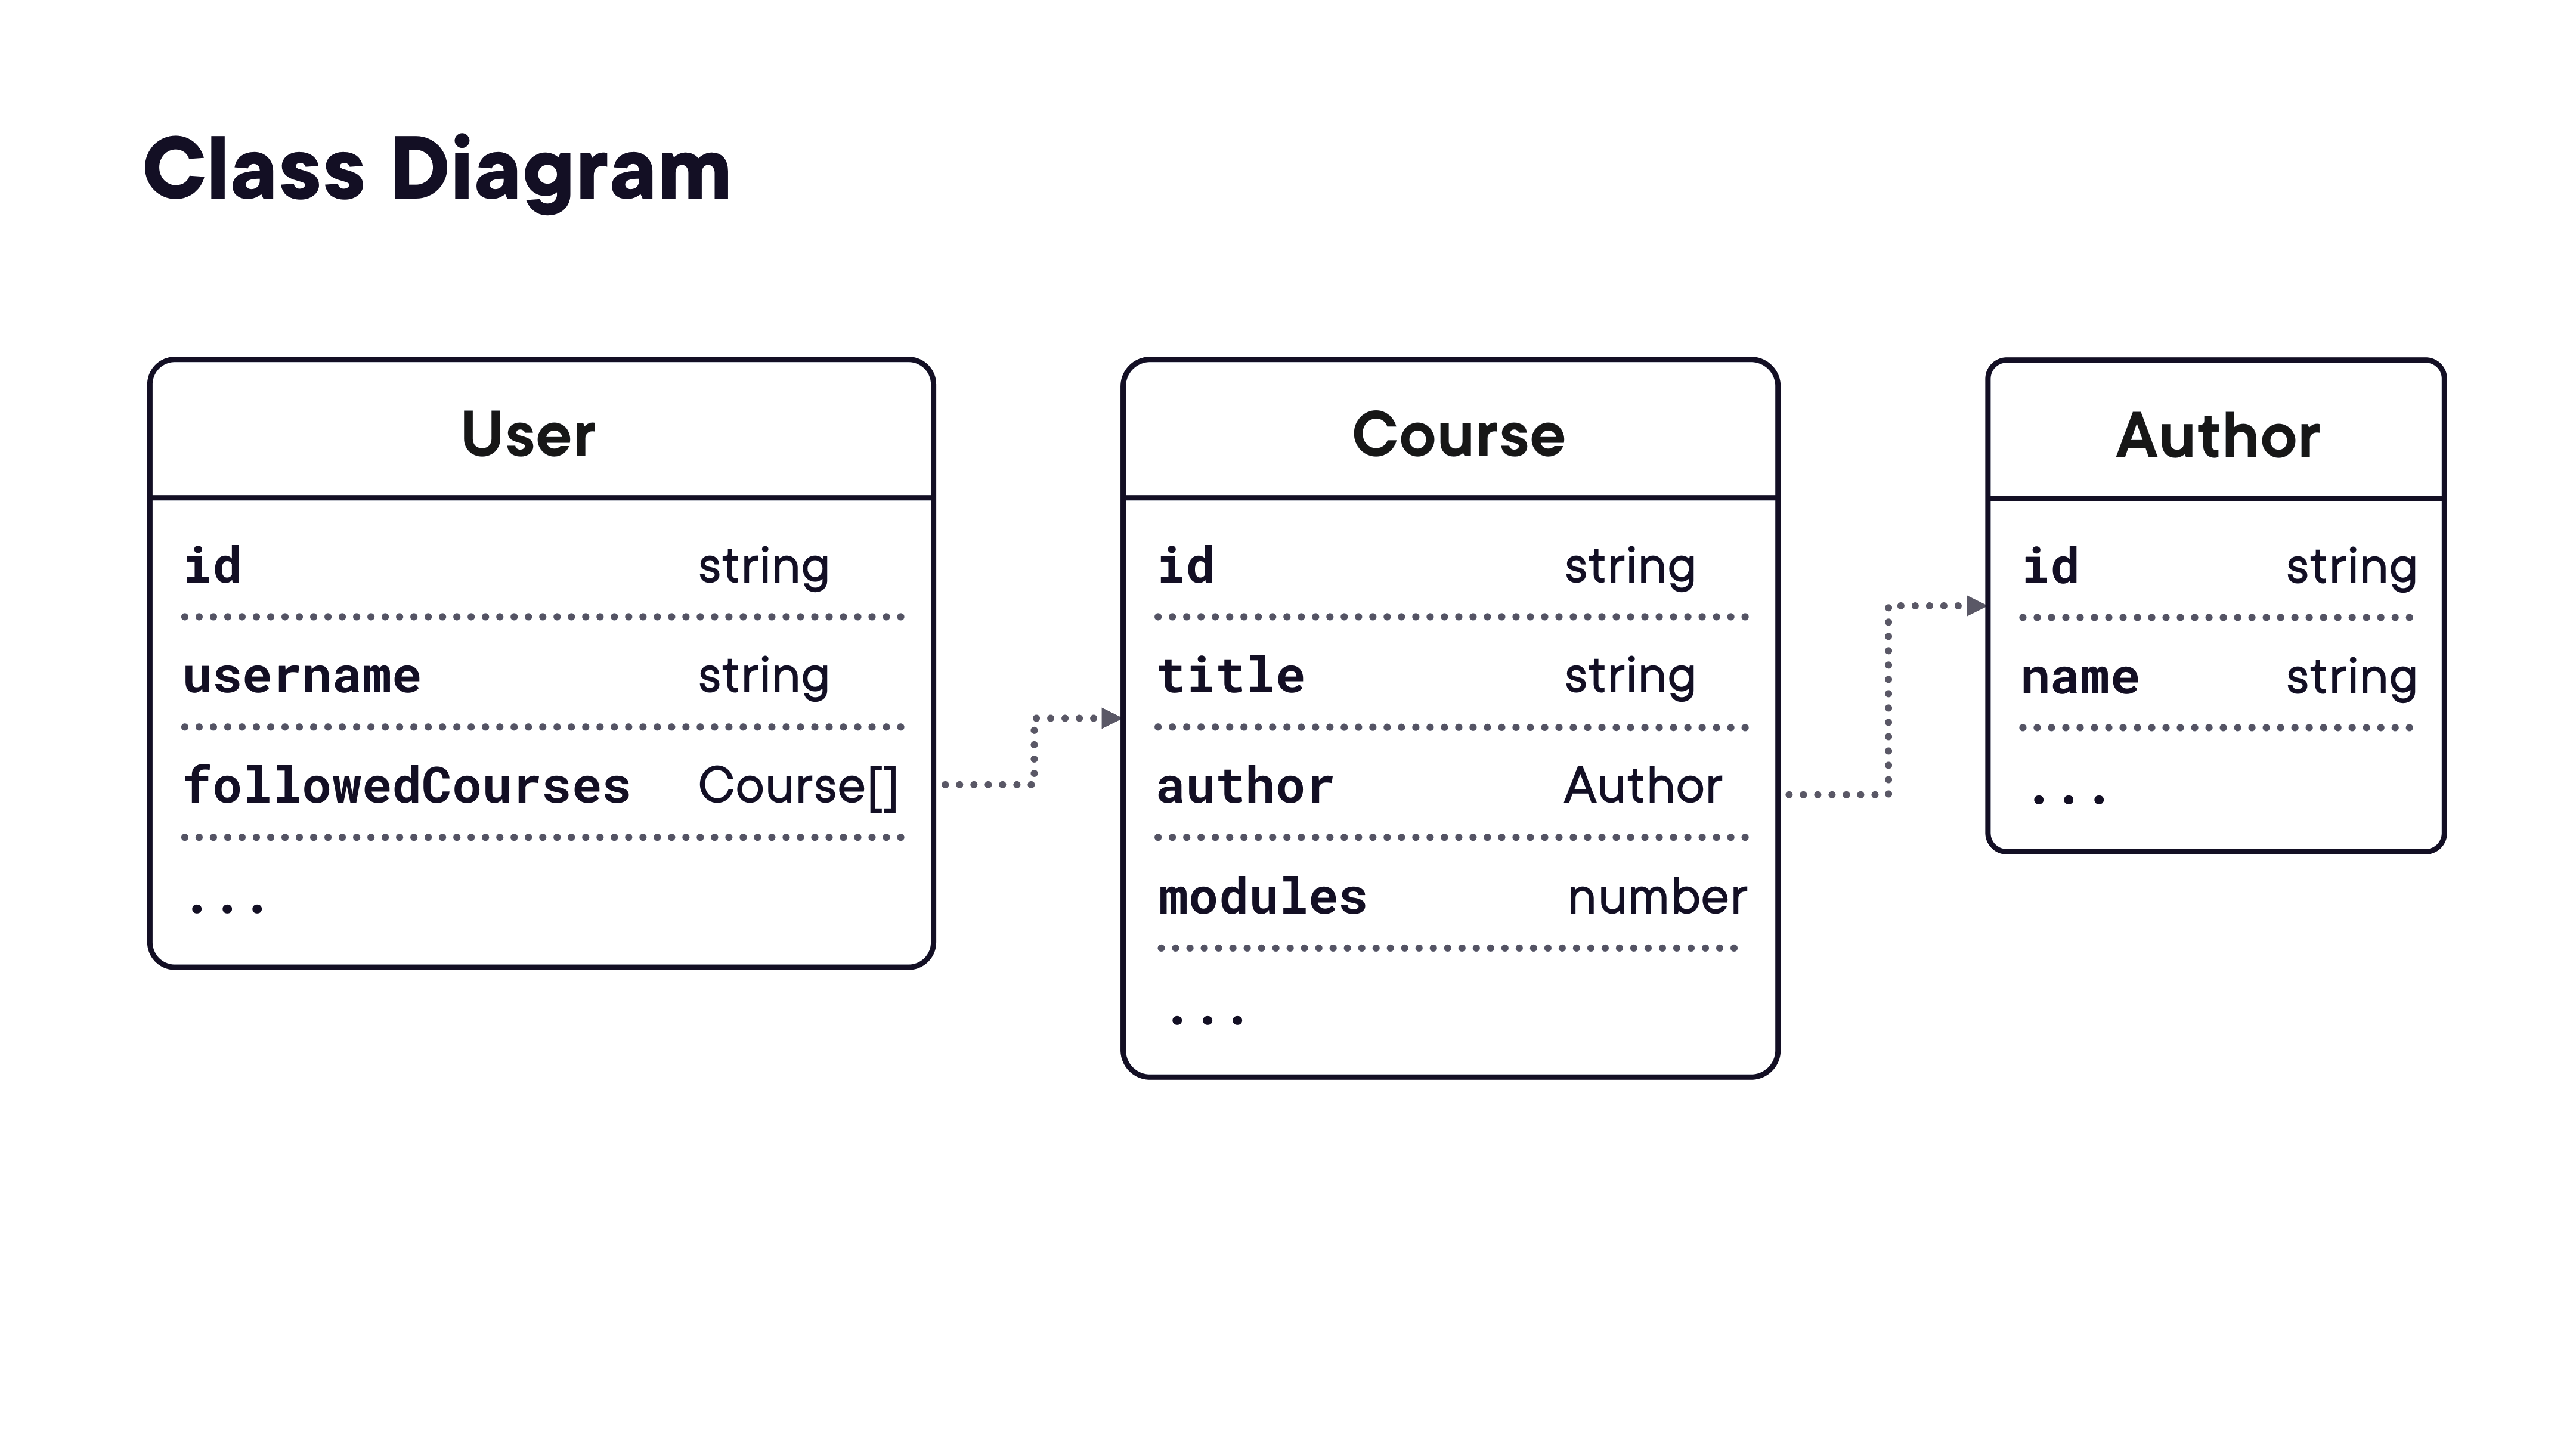

In [11]:
render_diagram(Path("assets/12-class-diagram.png"))

A `User` follows many `Course` objects (via an array `followedCourses: Course[]`). Each `Course` references an `Author` object. This illustrates all the concepts covered: objects as containers, nested references, arrays as properties, prototype chains providing methods on each type.

**Key takeaways from the course:**

**Objects**
- Objects are containers for other datatypes, passed via reference, and link to a prototype.
- All objects ultimately link to `Object.prototype`.
- Property access traverses the prototype chain.

**References**
- Primitives are stored on the stack; objects are stored on the heap with a pointer on the stack.
- Shallow copies share nested object references; deep copies are fully independent.
- Primitives are passed by value; objects are passed by reference.

**Arrays**
- Arrays are objects with zero-indexed numeric keys and `Array.prototype` methods.
- Keep arrays dense and homogeneous; avoid sparse arrays.
- Use `splice`/`toSpliced` to remove, `concat`/spread to combine, `slice` to extract.

**Iteration**
- Prefer `forEach`, `map`, `filter`, `reduce`, `find` over `for` loops for clarity.
- `find` → first match; `filter` → all matches; `map` → transform all; `reduce` → aggregate.
- `forEach` can't use `break`/`continue`; `for`, `for...in`, `for...of` can.
